# CELBC710 – Computational Intelligence Laboratory
## Task 4: Data Exploration and Preprocessing
### Smart Traffic Management System

**Objective:** Load a real-world traffic dataset, inspect its structure, identify missing values, duplicates and outliers, visualize important patterns, and prepare a cleaned dataset for further modeling.

**Dataset:** Embedded directly in this notebook

**Target column:** `action`

In [ ]:
# 1. Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Dataset

The dataset contains traffic conditions and the corresponding intelligent traffic-control action.

In [ ]:
# 2. Load the Dataset Directly

import pandas as pd
import numpy as np
from io import StringIO

# Original Smart Traffic Management dataset
data = """traffic_density,queue_length,waiting_time,emergency_vehicle,current_signal,average_speed,action
low,5,10,no,north,45,maintain
low,8,15,no,south,42,maintain
low,10,18,no,east,40,reduce_green
low,6,12,no,west,44,maintain
low,12,20,no,north,38,switch_signal
low,4,8,no,east,48,maintain
low,9,17,no,south,41,maintain
low,7,14,no,west,43,reduce_green
medium,20,35,no,north,30,extend_green
medium,25,40,no,south,28,extend_green
medium,22,45,no,east,27,extend_green
medium,30,50,no,west,25,extend_green
medium,18,32,no,north,32,maintain
medium,28,55,no,south,24,extend_green
medium,24,48,no,east,26,extend_green
medium,16,30,no,west,34,maintain
medium,35,60,no,north,22,extend_green
medium,26,42,no,east,29,extend_green
high,45,80,no,north,15,extend_green
high,50,100,no,south,12,extend_green
high,60,120,no,east,8,extend_green
high,55,90,no,west,10,extend_green
high,70,130,no,north,6,extend_green
high,65,110,no,south,9,extend_green
high,48,75,no,east,14,extend_green
high,52,85,no,west,13,extend_green
high,75,140,no,north,5,extend_green
high,80,150,no,east,4,extend_green
high,40,70,no,south,16,extend_green
high,45,95,no,west,11,extend_green
low,3,5,yes,north,50,emergency_priority
medium,20,35,yes,south,30,emergency_priority
high,45,80,yes,east,15,emergency_priority
low,6,10,yes,west,45,emergency_priority
medium,30,60,yes,north,22,emergency_priority
high,60,120,yes,south,8,emergency_priority
low,8,15,no,north,40,maintain
low,5,10,no,south,45,maintain
medium,15,25,no,east,35,maintain
medium,17,30,no,west,33,maintain
medium,20,45,no,north,29,extend_green
high,35,65,no,east,18,extend_green
high,40,70,no,west,16,extend_green
low,4,7,no,north,47,reduce_green
low,7,13,no,east,44,reduce_green
low,9,16,no,west,42,reduce_green
medium,12,22,no,south,36,switch_signal
medium,15,28,no,west,34,switch_signal
low,10,19,no,south,39,switch_signal"""

# Convert original embedded CSV data into DataFrame
base_df = pd.read_csv(StringIO(data))

# Reproducible random generation
np.random.seed(42)

# ---------------------------------------------------------
# Generate 1000 records
# ---------------------------------------------------------

df = pd.concat(
    [base_df] * (1000 // len(base_df) + 1),
    ignore_index=True
).iloc[:1000].copy()

# Shuffle records
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# ---------------------------------------------------------
# Add realistic variation to numerical features
# ---------------------------------------------------------

df["queue_length"] = (
    df["queue_length"] +
    np.random.randint(-3, 4, size=len(df))
).clip(lower=1)

df["waiting_time"] = (
    df["waiting_time"] +
    np.random.randint(-5, 6, size=len(df))
).clip(lower=1)

df["average_speed"] = (
    df["average_speed"] +
    np.random.randint(-3, 4, size=len(df))
).clip(lower=3)

# ---------------------------------------------------------
# Add 25 missing values
# ---------------------------------------------------------

missing_positions = [
    (10, "queue_length"),
    (25, "waiting_time"),
    (40, "average_speed"),
    (55, "traffic_density"),
    (70, "emergency_vehicle"),
    (85, "current_signal"),
    (100, "action"),
    (125, "queue_length"),
    (150, "waiting_time"),
    (175, "average_speed"),
    (200, "traffic_density"),
    (225, "emergency_vehicle"),
    (250, "current_signal"),
    (275, "action"),
    (300, "queue_length"),
    (325, "waiting_time"),
    (350, "average_speed"),
    (375, "traffic_density"),
    (400, "emergency_vehicle"),
    (425, "current_signal"),
    (450, "action"),
    (475, "queue_length"),
    (500, "waiting_time"),
    (525, "average_speed"),
    (550, "traffic_density")
]

for row, column in missing_positions:
    df.loc[row, column] = np.nan

# ---------------------------------------------------------
# Add 10 duplicate records
# ---------------------------------------------------------

duplicates = df.iloc[600:610].copy()

df = pd.concat(
    [df, duplicates],
    ignore_index=True
)

# ---------------------------------------------------------
# Add 5 outliers
# ---------------------------------------------------------

df.loc[700, "queue_length"] = 250
df.loc[701, "queue_length"] = 300
df.loc[702, "waiting_time"] = 500
df.loc[703, "waiting_time"] = 600
df.loc[704, "average_speed"] = 150

# ---------------------------------------------------------
# Shuffle final raw dataset
# ---------------------------------------------------------

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# ---------------------------------------------------------
# Display dataset information
# ---------------------------------------------------------

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully!
Number of rows: 1010
Number of columns: 7

Dataset columns:
['traffic_density', 'queue_length', 'waiting_time', 'emergency_vehicle', 'current_signal', 'average_speed', 'action']

First 5 records:


,traffic_density,queue_length,waiting_time,emergency_vehicle,current_signal,average_speed,action
0,high,52.0,84.0,no,west,10.0,extend_green
1,medium,19.0,38.0,yes,south,31.0,emergency_priority
2,high,64.0,114.0,no,south,8.0,extend_green
3,high,77.0,136.0,no,north,3.0,extend_green
4,low,6.0,12.0,no,east,41.0,reduce_green


In [ ]:
# Display first 5 records
df.head()

,traffic_density,queue_length,waiting_time,emergency_vehicle,current_signal,average_speed,action
0,high,52.0,84.0,no,west,10.0,extend_green
1,medium,19.0,38.0,yes,south,31.0,emergency_priority
2,high,64.0,114.0,no,south,8.0,extend_green
3,high,77.0,136.0,no,north,3.0,extend_green
4,low,6.0,12.0,no,east,41.0,reduce_green


In [ ]:
# Display last 5 records
df.tail()

,traffic_density,queue_length,waiting_time,emergency_vehicle,current_signal,average_speed,action
1005,medium,17.0,33.0,no,west,34.0,maintain
1006,low,6.0,15.0,no,north,43.0,maintain
1007,high,60.0,120.0,yes,south,7.0,emergency_priority
1008,medium,15.0,34.0,no,north,30.0,maintain
1009,low,4.0,11.0,no,east,49.0,maintain


## 3. Dataset Structure

Check the number of observations, column names, data types, and general information.

In [ ]:
# Dataset dimensions
print("Shape of dataset:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset information:")
df.info()

Shape of dataset: (1010, 7)

Column names:
['traffic_density', 'queue_length', 'waiting_time', 'emergency_vehicle', 'current_signal', 'average_speed', 'action']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   traffic_density    1006 non-null   object 
 1   queue_length       1006 non-null   float64
 2   waiting_time       1006 non-null   float64
 3   emergency_vehicle  1007 non-null   object 
 4   current_signal     1007 non-null   object 
 5   average_speed      1006 non-null   float64
 6   action             1007 non-null   object 
dtypes: float64(3), object(4)
memory usage: 55.4+ KB


In [ ]:
# Statistical summary of numerical columns
df.describe()

,queue_length,waiting_time,average_speed
count,1006.000000,1006.000000,1006.000000
mean,27.882704,51.336978,28.164016
std,23.787704,44.919616,14.048882
min,1.000000,1.000000,3.000000
25%,10.000000,17.000000,16.000000
50%,21.000000,39.000000,30.000000
75%,43.000000,75.750000,41.000000
max,300.000000,600.000000,150.000000


In [ ]:
# Statistical summary including categorical columns
df.describe(include="all")

,traffic_density,queue_length,waiting_time,emergency_vehicle,current_signal,average_speed,action
count,1006,1006.000000,1006.000000,1007,1007,1006.000000,1007
unique,3,NaN,NaN,2,4,NaN,5
top,medium,NaN,NaN,no,north,NaN,extend_green
freq,352,NaN,NaN,886,268,NaN,477
mean,NaN,27.882704,51.336978,NaN,NaN,28.164016,NaN
std,NaN,23.787704,44.919616,NaN,NaN,14.048882,NaN
min,NaN,1.000000,1.000000,NaN,NaN,3.000000,NaN
25%,NaN,10.000000,17.000000,NaN,NaN,16.000000,NaN
50%,NaN,21.000000,39.000000,NaN,NaN,30.000000,NaN
75%,NaN,43.000000,75.750000,NaN,NaN,41.000000,NaN


## 4. Check Missing Values

Missing values can affect analysis and machine-learning models. We check the number and percentage of missing values in every column.

In [ ]:
# Number of missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
traffic_density      4
queue_length         4
waiting_time         4
emergency_vehicle    3
current_signal       3
average_speed        4
action               3
dtype: int64


In [ ]:
# Percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage
})

missing_summary

,Missing Values,Percentage
traffic_density,4,0.39604
queue_length,4,0.39604
waiting_time,4,0.39604
emergency_vehicle,3,0.29703
current_signal,3,0.29703
average_speed,4,0.39604
action,3,0.29703


### Handling Missing Values

For this dataset, if missing values are found:
- Numerical columns are filled with the median.
- Categorical columns are filled with the mode.

If there are no missing values, the code simply reports that no imputation is required.

In [ ]:
# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['queue_length', 'waiting_time', 'average_speed']
Categorical columns: ['traffic_density', 'emergency_vehicle', 'current_signal', 'action']


In [ ]:
# Handle missing numerical values using median
for col in numerical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Handle missing categorical values using mode
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
traffic_density      0
queue_length         0
waiting_time         0
emergency_vehicle    0
current_signal       0
average_speed        0
action               0
dtype: int64


## 5. Check Duplicate Records

In [ ]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 32


In [ ]:
# Remove duplicate rows
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")
else:
    print("No duplicate rows found.")

print("Dataset shape after duplicate check:", df.shape)

Duplicates removed.
Dataset shape after duplicate check: (978, 7)


## 6. Check Unique Values

This helps understand the categories present in traffic density, emergency-vehicle status, signal direction, and action.

In [ ]:
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


traffic_density:
traffic_density
medium    341
low       321
high      316
Name: count, dtype: int64

emergency_vehicle:
emergency_vehicle
no     859
yes    119
Name: count, dtype: int64

current_signal:
current_signal
north    262
west     242
south    238
east     236
Name: count, dtype: int64

action:
action
extend_green          462
maintain              217
emergency_priority    118
reduce_green          102
switch_signal          79
Name: count, dtype: int64


## 7. Outlier Detection

The numerical variables are checked for possible outliers using the Interquartile Range (IQR) method.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

In [ ]:
# Function to detect outliers using IQR
def detect_outliers_iqr(data, columns):
    results = {}

    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]

        results[col] = {
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Outlier Count": len(outliers)
        }

    return pd.DataFrame(results).T

outlier_summary = detect_outliers_iqr(df, numerical_cols)
outlier_summary

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
queue_length,10.00,43.0,33.00,-39.500,92.500,2.0
waiting_time,17.25,76.0,58.75,-70.875,164.125,2.0
average_speed,15.25,41.0,25.75,-23.375,79.625,1.0


### Boxplots for Numerical Features

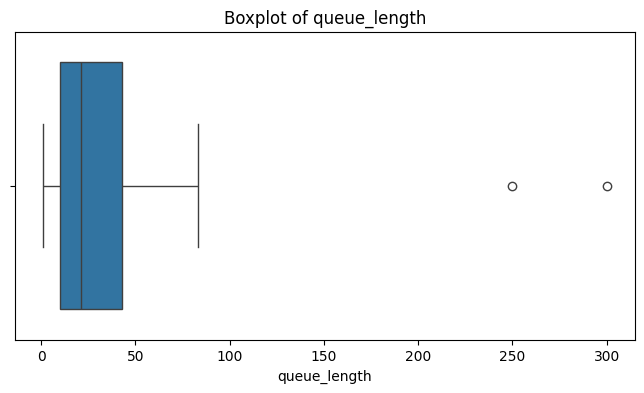

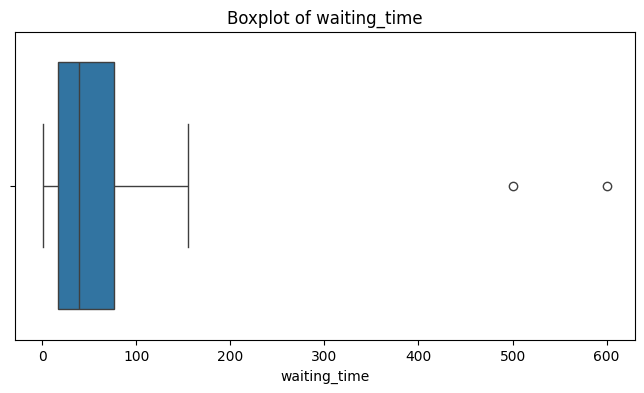

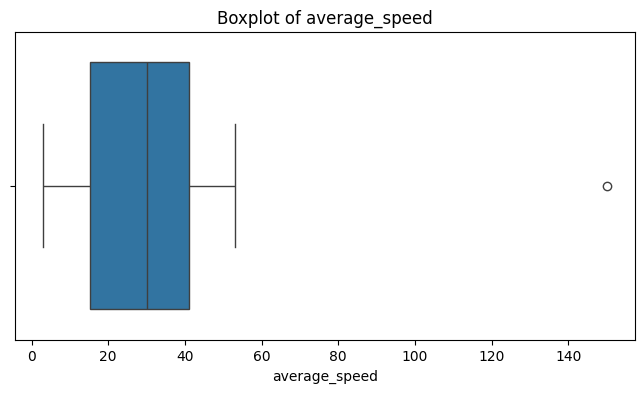

In [ ]:
# Boxplots
for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

## 8. Exploratory Data Analysis (EDA)

### 8.1 Traffic Density Distribution

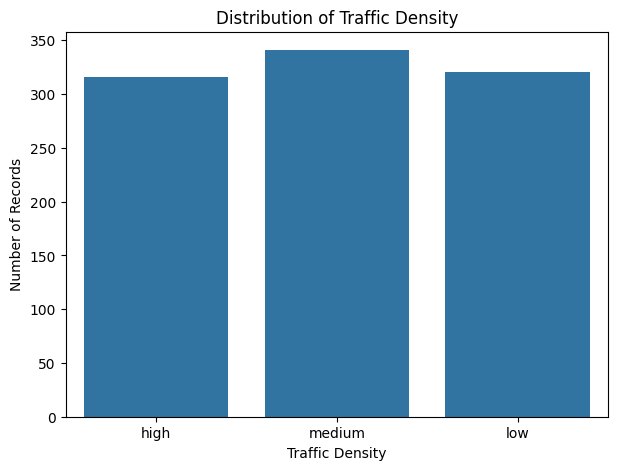

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="traffic_density")
plt.title("Distribution of Traffic Density")
plt.xlabel("Traffic Density")
plt.ylabel("Number of Records")
plt.show()

### 8.2 Traffic-Control Action Distribution

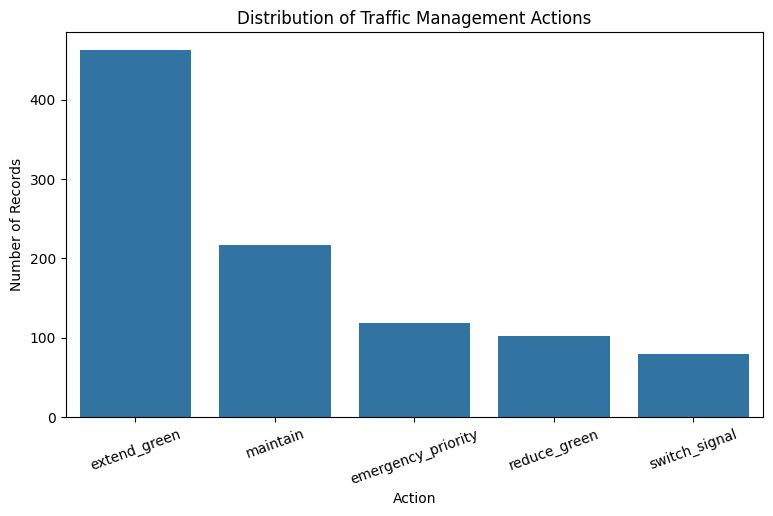

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="action", order=df["action"].value_counts().index)
plt.title("Distribution of Traffic Management Actions")
plt.xlabel("Action")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.show()

### 8.3 Average Speed Distribution

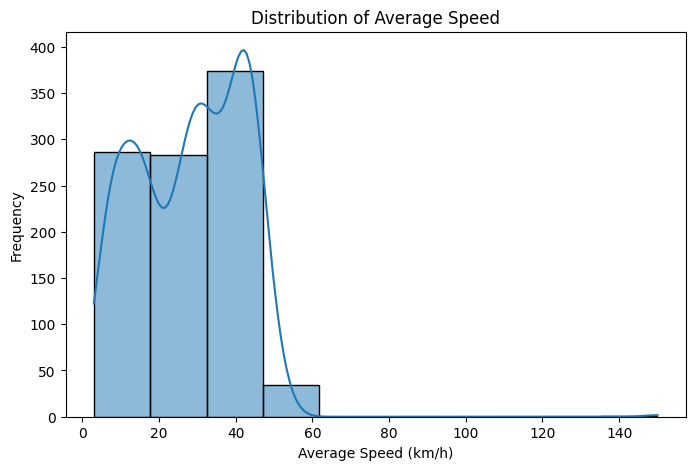

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="average_speed", bins=10, kde=True)
plt.title("Distribution of Average Speed")
plt.xlabel("Average Speed (km/h)")
plt.ylabel("Frequency")
plt.show()

### 8.4 Queue Length Distribution

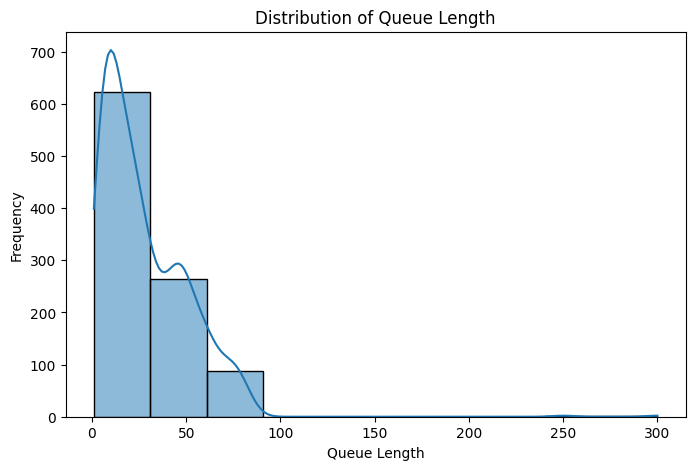

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="queue_length", bins=10, kde=True)
plt.title("Distribution of Queue Length")
plt.xlabel("Queue Length")
plt.ylabel("Frequency")
plt.show()

### 8.5 Waiting Time Distribution

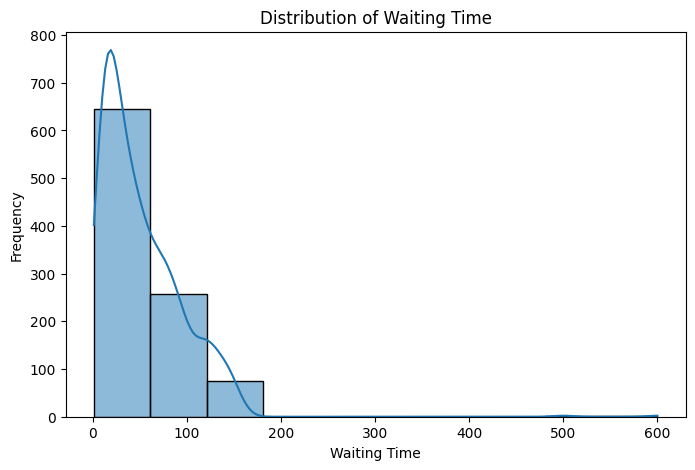

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="waiting_time", bins=10, kde=True)
plt.title("Distribution of Waiting Time")
plt.xlabel("Waiting Time")
plt.ylabel("Frequency")
plt.show()

### 8.6 Traffic Density vs Average Speed

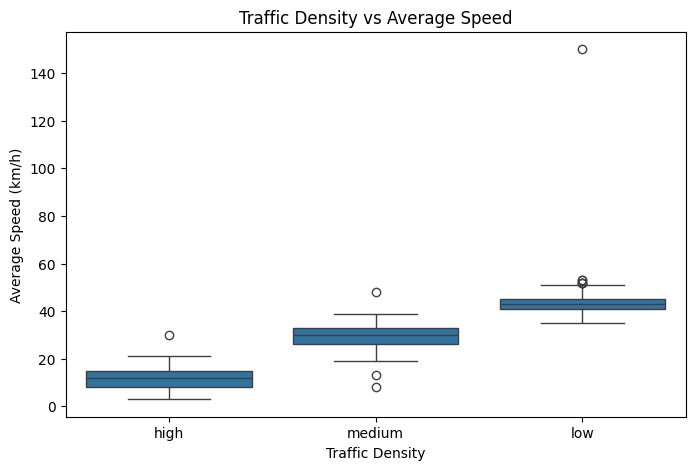

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="traffic_density", y="average_speed")
plt.title("Traffic Density vs Average Speed")
plt.xlabel("Traffic Density")
plt.ylabel("Average Speed (km/h)")
plt.show()

### 8.7 Traffic Density vs Queue Length

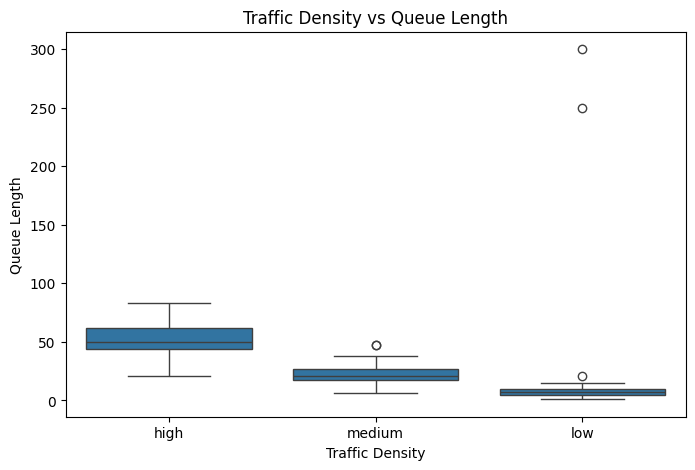

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="traffic_density", y="queue_length")
plt.title("Traffic Density vs Queue Length")
plt.xlabel("Traffic Density")
plt.ylabel("Queue Length")
plt.show()

### 8.8 Emergency Vehicle vs Action

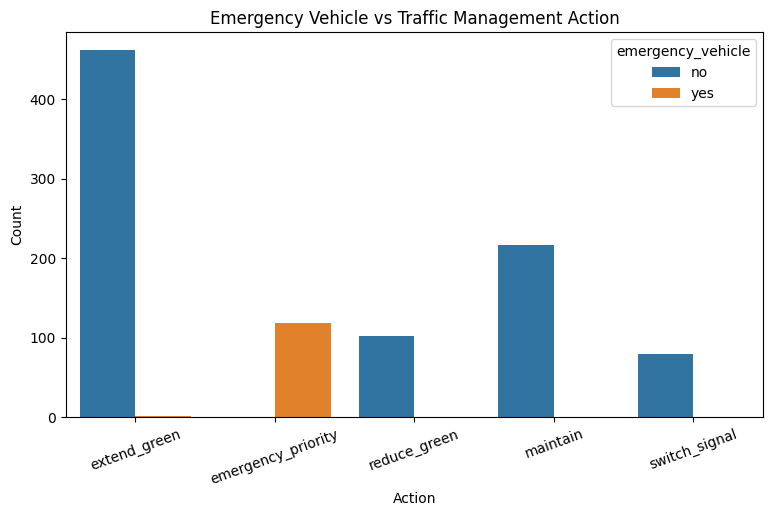

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="action", hue="emergency_vehicle")
plt.title("Emergency Vehicle vs Traffic Management Action")
plt.xlabel("Action")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

### 8.9 Current Signal vs Action

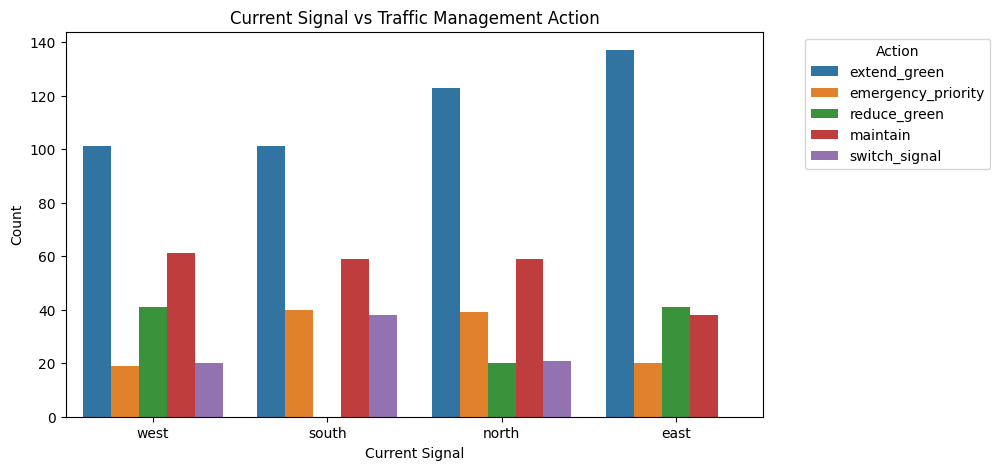

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="current_signal", hue="action")
plt.title("Current Signal vs Traffic Management Action")
plt.xlabel("Current Signal")
plt.ylabel("Count")
plt.legend(title="Action", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

### 8.10 Correlation Heatmap

Correlation is calculated for numerical variables to identify relationships between traffic measurements.

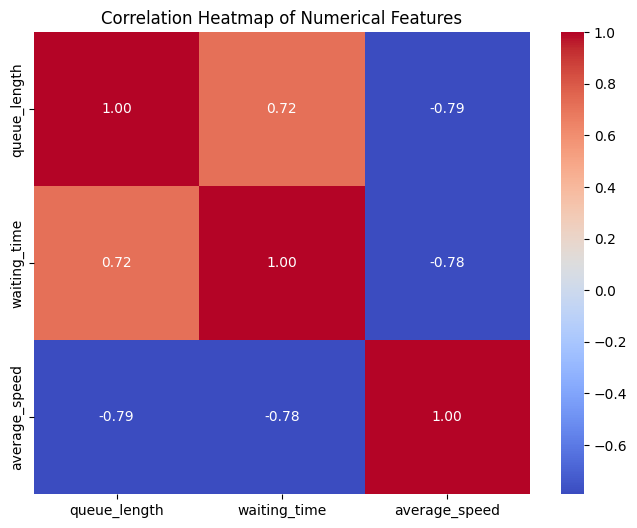

In [ ]:
plt.figure(figsize=(8, 6))
correlation_matrix = df[numerical_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

## 9. Prepare a Clean Dataset

For Task 4, categorical columns can be encoded and numerical features can be scaled so that the resulting dataset is ready for the next stage of modeling.

In [ ]:
# Create a copy for preprocessing
clean_df = df.copy()

# Encode binary emergency_vehicle column
clean_df["emergency_vehicle"] = clean_df["emergency_vehicle"].map({
    "no": 0,
    "yes": 1
})

# One-hot encode current_signal
clean_df = pd.get_dummies(
    clean_df,
    columns=["current_signal"],
    dtype=int
)

# One-hot encode traffic_density
clean_df = pd.get_dummies(
    clean_df,
    columns=["traffic_density"],
    dtype=int
)

print("Encoded dataset:")
clean_df.head()

Encoded dataset:


,queue_length,waiting_time,emergency_vehicle,average_speed,action,current_signal_east,current_signal_north,current_signal_south,current_signal_west,traffic_density_high,traffic_density_low,traffic_density_medium
0,52.0,84.0,0,10.0,extend_green,0,0,0,1,1,0,0
1,19.0,38.0,1,31.0,emergency_priority,0,0,1,0,0,0,1
2,64.0,114.0,0,8.0,extend_green,0,0,1,0,1,0,0
3,77.0,136.0,0,3.0,extend_green,0,1,0,0,1,0,0
4,6.0,12.0,0,41.0,reduce_green,1,0,0,0,0,1,0


## 10. Feature Scaling

StandardScaler transforms numerical features so that they have approximately zero mean and unit variance.

In [ ]:
# Numerical columns to scale
scale_cols = [
    "queue_length",
    "waiting_time",
    "average_speed"
]

scaler = StandardScaler()

clean_df[scale_cols] = scaler.fit_transform(clean_df[scale_cols])

print("Scaled numerical features:")
clean_df[scale_cols].head()

Scaled numerical features:


,queue_length,waiting_time,average_speed
0,1.009718,0.724881,-1.293215
1,-0.374164,-0.298111,0.201862
2,1.512948,1.392051,-1.435603
3,2.058114,1.881308,-1.791574
4,-0.919329,-0.876325,0.913804


## 11. Final Cleaned Dataset

In [ ]:
print("Final dataset shape:", clean_df.shape)
print("\nFinal columns:")
print(clean_df.columns.tolist())

print("\nFirst five records:")
clean_df.head()

Final dataset shape: (978, 12)

Final columns:
['queue_length', 'waiting_time', 'emergency_vehicle', 'average_speed', 'action', 'current_signal_east', 'current_signal_north', 'current_signal_south', 'current_signal_west', 'traffic_density_high', 'traffic_density_low', 'traffic_density_medium']

First five records:


,queue_length,waiting_time,emergency_vehicle,average_speed,action,current_signal_east,current_signal_north,current_signal_south,current_signal_west,traffic_density_high,traffic_density_low,traffic_density_medium
0,1.009718,0.724881,0,-1.293215,extend_green,0,0,0,1,1,0,0
1,-0.374164,-0.298111,1,0.201862,emergency_priority,0,0,1,0,0,0,1
2,1.512948,1.392051,0,-1.435603,extend_green,0,0,1,0,1,0,0
3,2.058114,1.881308,0,-1.791574,extend_green,0,1,0,0,1,0,0
4,-0.919329,-0.876325,0,0.913804,reduce_green,1,0,0,0,0,1,0


In [ ]:
# Check for missing values after preprocessing
print("Missing values after preprocessing:")
print(clean_df.isnull().sum())

Missing values after preprocessing:
queue_length              0
waiting_time              0
emergency_vehicle         0
average_speed             0
action                    0
current_signal_east       0
current_signal_north      0
current_signal_south      0
current_signal_west       0
traffic_density_high      0
traffic_density_low       0
traffic_density_medium    0
dtype: int64


## 12. Save Cleaned Dataset

The cleaned dataset is saved so that **Task 5 (Feature Engineering and Feature Selection)** can use it directly.

In [ ]:
output_file = "smart_traffic_cleaned_task4.csv"

clean_df.to_csv(output_file, index=False)

print(f"Cleaned dataset saved successfully as: {output_file}")

Cleaned dataset saved successfully as: smart_traffic_cleaned_task4.csv


# Task 4 Conclusion

The Smart Traffic Management dataset was successfully loaded and explored. Dataset structure, feature types, summary statistics, missing values, duplicate records, and outliers were examined. Appropriate visualizations were created to understand traffic patterns. Categorical variables were encoded and numerical variables were standardized. The resulting cleaned dataset was saved for further feature engineering and machine-learning tasks.

**Task 4 Learning Outcome:** The dataset is now prepared for Task 5, where feature extraction, transformation, feature selection, feature importance, and train-test splitting will be performed.

Task 4 cleaned dataset:
   queue_length  waiting_time  emergency_vehicle  average_speed  \
0      1.009718      0.724881                  0      -1.293215   
1     -0.374164     -0.298111                  1       0.201862   
2      1.512948      1.392051                  0      -1.435603   
3      2.058114      1.881308                  0      -1.791574   
4     -0.919329     -0.876325                  0       0.913804   

               action  current_signal_east  current_signal_north  \
0        extend_green                    0                     0   
1  emergency_priority                    0                     0   
2        extend_green                    0                     0   
3        extend_green                    0                     1   
4        reduce_green                    1                     0   

   current_signal_south  current_signal_west  traffic_density_high  \
0                     0                    1                     1   
1                     1 

ValueError: A given column is not a column of the dataframe

In [ ]:
# ============================================================
# TASK 5 - FEATURE PREPARATION
# Uses the already-cleaned dataset from Task 4
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier


# ------------------------------------------------------------
# 1. USE CLEANED DATASET FROM TASK 4
# ------------------------------------------------------------

print("Dataset Shape:", clean_df.shape)

print("\nDataset Columns:")
print(clean_df.columns.tolist())


# ------------------------------------------------------------
# 2. SEPARATE FEATURES AND TARGET
# ------------------------------------------------------------

X = clean_df.drop("action", axis=1)
y = clean_df["action"]

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget: action")


# ------------------------------------------------------------
# 3. ENCODE TARGET ONLY
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("\nTarget Classes:")
print(label_encoder.classes_)

print("\nEncoded Target Sample:")
print(y_encoded[:10])


# ------------------------------------------------------------
# 4. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape :", X_test.shape)


# ------------------------------------------------------------
# 5. FEATURE SELECTION USING MUTUAL INFORMATION
# ------------------------------------------------------------

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature": X_train.columns,
    "MI_Score": mi_scores
})

mi_df = mi_df.sort_values(
    "MI_Score",
    ascending=False
)

print("\nFeature Selection Scores:")
display(mi_df)


# ------------------------------------------------------------
# 6. SELECT TOP 8 FEATURES
# ------------------------------------------------------------

top_features = mi_df.head(8)["Feature"].tolist()

print("\nSelected Top 8 Features:")
print(top_features)


X_train_selected = X_train[top_features].copy()
X_test_selected = X_test[top_features].copy()


print("\nFinal Training Feature Matrix:")
display(X_train_selected.head())

print("\nTraining Shape:", X_train_selected.shape)
print("Testing Shape :", X_test_selected.shape)


# ------------------------------------------------------------
# 7. RANDOM FOREST FEATURE IMPORTANCE
# ------------------------------------------------------------

rf_feature_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_feature_model.fit(
    X_train_selected,
    y_train
)

feature_importance = pd.DataFrame({
    "Feature": X_train_selected.columns,
    "Importance": rf_feature_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print("\nFeature Importance:")
display(feature_importance)


print("\n======================================")
print("TASK 5 COMPLETED SUCCESSFULLY")
print("======================================")

Dataset Shape: (978, 12)

Dataset Columns:
['queue_length', 'waiting_time', 'emergency_vehicle', 'average_speed', 'action', 'current_signal_east', 'current_signal_north', 'current_signal_south', 'current_signal_west', 'traffic_density_high', 'traffic_density_low', 'traffic_density_medium']

Feature Columns:
['queue_length', 'waiting_time', 'emergency_vehicle', 'average_speed', 'current_signal_east', 'current_signal_north', 'current_signal_south', 'current_signal_west', 'traffic_density_high', 'traffic_density_low', 'traffic_density_medium']

Target: action

Target Classes:
['emergency_priority' 'extend_green' 'maintain' 'reduce_green'
 'switch_signal']

Encoded Target Sample:
[1 0 1 1 3 2 3 1 2 1]

Training Shape: (782, 11)
Testing Shape : (196, 11)

Feature Selection Scores:


,Feature,MI_Score
1,waiting_time,0.738440
0,queue_length,0.698587
3,average_speed,0.686469
9,traffic_density_low,0.388152
2,emergency_vehicle,0.326684
8,traffic_density_high,0.227658
4,current_signal_east,0.039170
10,traffic_density_medium,0.023040
7,current_signal_west,0.003036
6,current_signal_south,0.000000



Selected Top 8 Features:
['waiting_time', 'queue_length', 'average_speed', 'traffic_density_low', 'emergency_vehicle', 'traffic_density_high', 'current_signal_east', 'traffic_density_medium']

Final Training Feature Matrix:


,waiting_time,queue_length,average_speed,traffic_density_low,emergency_vehicle,traffic_density_high,current_signal_east,traffic_density_medium
143,-0.920803,-1.045137,1.625745,1,1,0,0,0
465,-0.987520,-0.961265,0.984998,1,0,0,0,0
495,-0.898564,-0.793522,0.913804,1,0,0,0,0
203,-0.520501,-0.499971,0.557833,0,0,0,0,1
14,0.391297,0.506489,-0.794856,0,0,1,0,0



Training Shape: (782, 8)
Testing Shape : (196, 8)

Feature Importance:


,Feature,Importance
1,queue_length,0.249262
0,waiting_time,0.244719
4,emergency_vehicle,0.213626
2,average_speed,0.193794
6,current_signal_east,0.038792
3,traffic_density_low,0.033023
5,traffic_density_high,0.014541
7,traffic_density_medium,0.012244



TASK 5 COMPLETED SUCCESSFULLY


Task 4 Cleaned Dataset:


,queue_length,waiting_time,emergency_vehicle,average_speed,action,current_signal_east,current_signal_north,current_signal_south,current_signal_west,traffic_density_high,traffic_density_low,traffic_density_medium
0,1.009718,0.724881,0,-1.293215,extend_green,0,0,0,1,1,0,0
1,-0.374164,-0.298111,1,0.201862,emergency_priority,0,0,1,0,0,0,1
2,1.512948,1.392051,0,-1.435603,extend_green,0,0,1,0,1,0,0
3,2.058114,1.881308,0,-1.791574,extend_green,0,1,0,0,1,0,0
4,-0.919329,-0.876325,0,0.913804,reduce_green,1,0,0,0,0,1,0



Dataset Shape: (978, 12)

Feature Columns:
['queue_length', 'waiting_time', 'emergency_vehicle', 'average_speed', 'current_signal_east', 'current_signal_north', 'current_signal_south', 'current_signal_west', 'traffic_density_high', 'traffic_density_low', 'traffic_density_medium']

Target Column:
action

Target Classes:
['emergency_priority' 'extend_green' 'maintain' 'reduce_green'
 'switch_signal']

Encoded Target:
[1 0 1 1 3 2 3 1 2 1]


ValueError: A given column is not a column of the dataframe

Task 4 Cleaned Dataset:


,queue_length,waiting_time,emergency_vehicle,average_speed,action,current_signal_east,current_signal_north,current_signal_south,current_signal_west,traffic_density_high,traffic_density_low,traffic_density_medium
0,1.009718,0.724881,0,-1.293215,extend_green,0,0,0,1,1,0,0
1,-0.374164,-0.298111,1,0.201862,emergency_priority,0,0,1,0,0,0,1
2,1.512948,1.392051,0,-1.435603,extend_green,0,0,1,0,1,0,0
3,2.058114,1.881308,0,-1.791574,extend_green,0,1,0,0,1,0,0
4,-0.919329,-0.876325,0,0.913804,reduce_green,1,0,0,0,0,1,0



Dataset Shape: (978, 12)

Feature Columns:
['queue_length', 'waiting_time', 'emergency_vehicle', 'average_speed', 'current_signal_east', 'current_signal_north', 'current_signal_south', 'current_signal_west', 'traffic_density_high', 'traffic_density_low', 'traffic_density_medium']

Target Column:
action

Target Classes:
['emergency_priority' 'extend_green' 'maintain' 'reduce_green'
 'switch_signal']

Encoded Target:
[1 0 1 1 3 2 3 1 2 1]

Feature Matrix After Task 4 Transformation:


,queue_length,waiting_time,emergency_vehicle,average_speed,current_signal_east,current_signal_north,current_signal_south,current_signal_west,traffic_density_high,traffic_density_low,traffic_density_medium
0,1.009718,0.724881,0,-1.293215,0,0,0,1,1,0,0
1,-0.374164,-0.298111,1,0.201862,0,0,1,0,0,0,1
2,1.512948,1.392051,0,-1.435603,0,0,1,0,1,0,0
3,2.058114,1.881308,0,-1.791574,0,1,0,0,1,0,0
4,-0.919329,-0.876325,0,0.913804,1,0,0,0,0,1,0



Feature Matrix Shape:
(978, 11)

TRAIN-TEST SPLIT
Training Features: (782, 11)
Testing Features : (196, 11)
Training Target  : (782,)
Testing Target   : (196,)

FEATURE SELECTION
Mutual Information Scores:


...

,waiting_time,queue_length,average_speed,traffic_density_low,emergency_vehicle,traffic_density_high,current_signal_east,traffic_density_medium
143,-0.920803,-1.045137,1.625745,1,1,0,0,0
465,-0.987520,-0.961265,0.984998,1,0,0,0,0
495,-0.898564,-0.793522,0.913804,1,0,0,0,0
203,-0.520501,-0.499971,0.557833,0,0,0,0,1
14,0.391297,0.506489,-0.794856,0,0,1,0,0



Testing Feature Matrix:


,waiting_time,queue_length,average_speed,traffic_density_low,emergency_vehicle,traffic_density_high,current_signal_east,traffic_density_medium
324,0.680403,1.009718,-1.150826,0,0,1,0,0
244,0.635925,0.841975,-0.866050,0,0,1,0,0
704,0.969510,0.800039,-1.364409,0,0,1,0,0
955,-0.653935,-0.583843,0.486639,0,0,0,0,1
501,2.103698,2.309729,-1.791574,0,0,1,1,0



Final Training Shape: (782, 8)
Final Testing Shape: (196, 8)

FEATURE IMPORTANCE


,Feature,Importance
0,queue_length,0.249262
1,waiting_time,0.244719
2,emergency_vehicle,0.213626
3,average_speed,0.193794
4,current_signal_east,0.038792
5,traffic_density_low,0.033023
6,traffic_density_high,0.014541
7,traffic_density_medium,0.012244


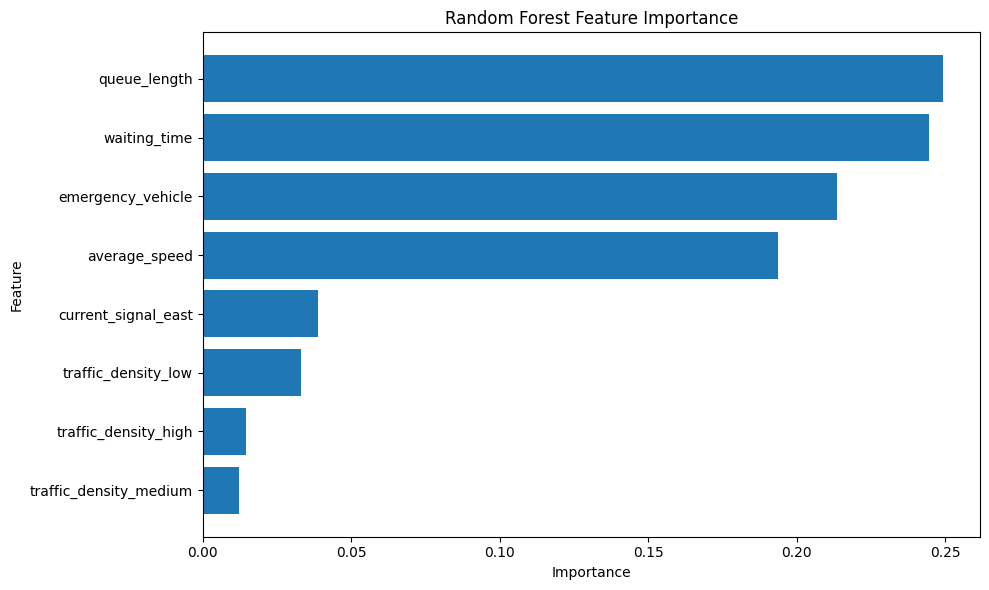


FINAL MODEL-READY DATA

X_train:
(782, 8)

X_test:
(196, 8)

y_train:
(782,)

y_test:
(196,)

Task 5 Completed Successfully!


In [ ]:
# ============================================================
# CELBC710 – TASK 5
# Feature Selection, Feature Importance & Train-Test Split
# Smart Traffic Management System
# Continue directly from Task 4
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier


# ============================================================
# 1. Task 4 Cleaned Dataset
# ============================================================

print("Task 4 Cleaned Dataset:")
display(clean_df.head())

print("\nDataset Shape:", clean_df.shape)


# ============================================================
# 2. Separate Features and Target
# ============================================================

# 'action' is the target variable
X = clean_df.drop("action", axis=1)

y = clean_df["action"]


print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Column:")
print("action")


# ============================================================
# 3. Encode Target Variable
# ============================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)


print("\nTarget Classes:")
print(label_encoder.classes_)

print("\nEncoded Target:")
print(y_encoded[:10])


# ============================================================
# 4. Feature Extraction / Transformation
# ============================================================

# Task 4 has ALREADY performed:
# - categorical encoding
# - numerical scaling
#
# Therefore, the current X is already
# machine-learning-ready.

print("\nFeature Matrix After Task 4 Transformation:")
display(X.head())

print("\nFeature Matrix Shape:")
print(X.shape)


# ============================================================
# 5. Train-Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)


print("\n======================================")
print("TRAIN-TEST SPLIT")
print("======================================")

print("Training Features:", X_train.shape)
print("Testing Features :", X_test.shape)

print("Training Target  :", y_train.shape)
print("Testing Target   :", y_test.shape)


# ============================================================
# 6. Feature Selection – Mutual Information
# ============================================================

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)


mi_results = pd.DataFrame({
    "Feature": X_train.columns,
    "MI_Score": mi_scores
})


# Sort from most relevant to least relevant
mi_results = mi_results.sort_values(
    by="MI_Score",
    ascending=False
).reset_index(drop=True)


print("\n======================================")
print("FEATURE SELECTION")
print("======================================")

print("Mutual Information Scores:")

display(mi_results)


# ============================================================
# 7. Select Top Relevant Features
# ============================================================

# Select top 8 features
top_k = min(8, len(mi_results))

selected_features = mi_results.head(
    top_k
)["Feature"].tolist()


print("\nSelected Top Features:")

for i, feature in enumerate(
    selected_features,
    start=1
):
    print(i, ".", feature)


# Create selected training and testing matrices

X_train_selected = X_train[
    selected_features
]

X_test_selected = X_test[
    selected_features
]


# ============================================================
# 8. Final Selected Feature Matrix
# ============================================================

print("\n======================================")
print("FINAL SELECTED FEATURE MATRIX")
print("======================================")

print("\nSelected Features:")
print(selected_features)

print("\nTraining Feature Matrix:")
display(X_train_selected.head())

print("\nTesting Feature Matrix:")
display(X_test_selected.head())

print("\nFinal Training Shape:",
      X_train_selected.shape)

print("Final Testing Shape:",
      X_test_selected.shape)


# ============================================================
# 9. Feature Importance – Random Forest
# ============================================================

rf_feature_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


rf_feature_model.fit(
    X_train_selected,
    y_train
)


feature_importance = pd.DataFrame({
    "Feature": X_train_selected.columns,
    "Importance": rf_feature_model.feature_importances_
})


feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


print("\n======================================")
print("FEATURE IMPORTANCE")
print("======================================")

display(feature_importance)


# ============================================================
# 10. Feature Importance Visualization
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ============================================================
# 11. Final Model-Ready Data
# ============================================================

print("\n======================================")
print("FINAL MODEL-READY DATA")
print("======================================")

print("\nX_train:")
print(X_train_selected.shape)

print("\nX_test:")
print(X_test_selected.shape)

print("\ny_train:")
print(y_train.shape)

print("\ny_test:")
print(y_test.shape)

print("\nTask 5 Completed Successfully!")

Final Training Feature Matrix:


,waiting_time,queue_length,average_speed,traffic_density_low,emergency_vehicle,traffic_density_high,current_signal_east,traffic_density_medium
143,-0.920803,-1.045137,1.625745,1,1,0,0,0
465,-0.987520,-0.961265,0.984998,1,0,0,0,0
495,-0.898564,-0.793522,0.913804,1,0,0,0,0
203,-0.520501,-0.499971,0.557833,0,0,0,0,1
14,0.391297,0.506489,-0.794856,0,0,1,0,0



Training Shape: (782, 8)
Testing Shape : (196, 8)

Logistic Regression Training Completed!
Decision Tree Training Completed!
Random Forest Training Completed!

Logistic Regression
Accuracy  : 0.801
Precision : 0.7497
Recall    : 0.801
F1-Score  : 0.7673

Classification Report:
                    precision    recall  f1-score   support

emergency_priority       0.96      1.00      0.98        24
      extend_green       0.94      0.99      0.96        93
          maintain       0.54      0.77      0.63        43
      reduce_green       0.67      0.40      0.50        20
     switch_signal       0.00      0.00      0.00        16

          accuracy                           0.80       196
         macro avg       0.62      0.63      0.62       196
      weighted avg       0.75      0.80      0.77       196


Decision Tree
Accuracy  : 0.8622
Precision : 0.8759
Recall    : 0.8622
F1-Score  : 0.8457

Classification Report:
                    precision    recall  f1-score   support

em

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.801020,0.749703,0.801020,0.767297
1,Decision Tree,0.862245,0.875931,0.862245,0.845713
2,Random Forest,0.882653,0.891567,0.882653,0.880743


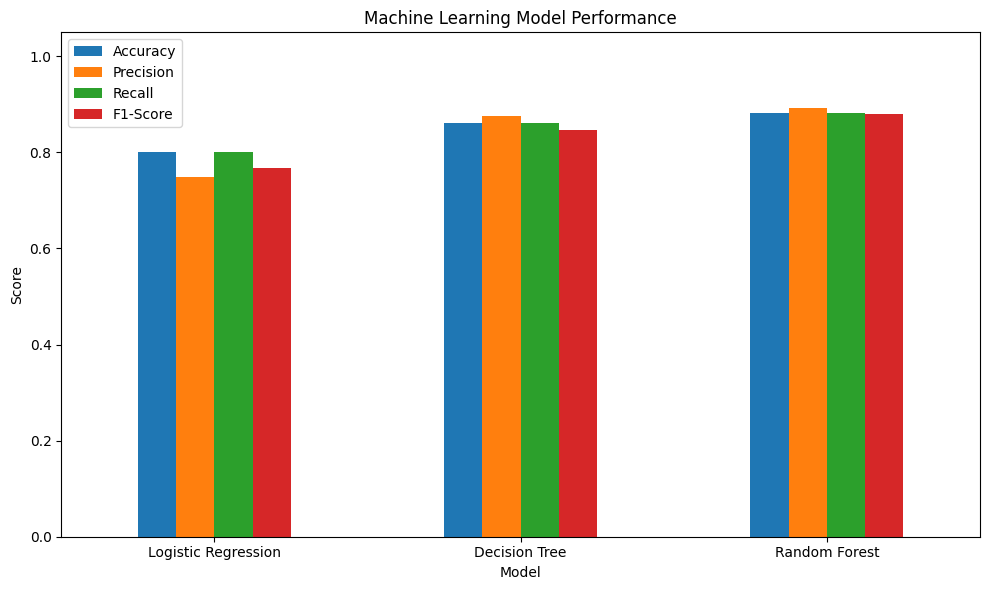


RANDOM FOREST CONFUSION MATRIX
[[24  0  0  0  0]
 [ 1 90  2  0  0]
 [ 0  3 37  2  1]
 [ 0  0  8 12  0]
 [ 0  0  6  0 10]]


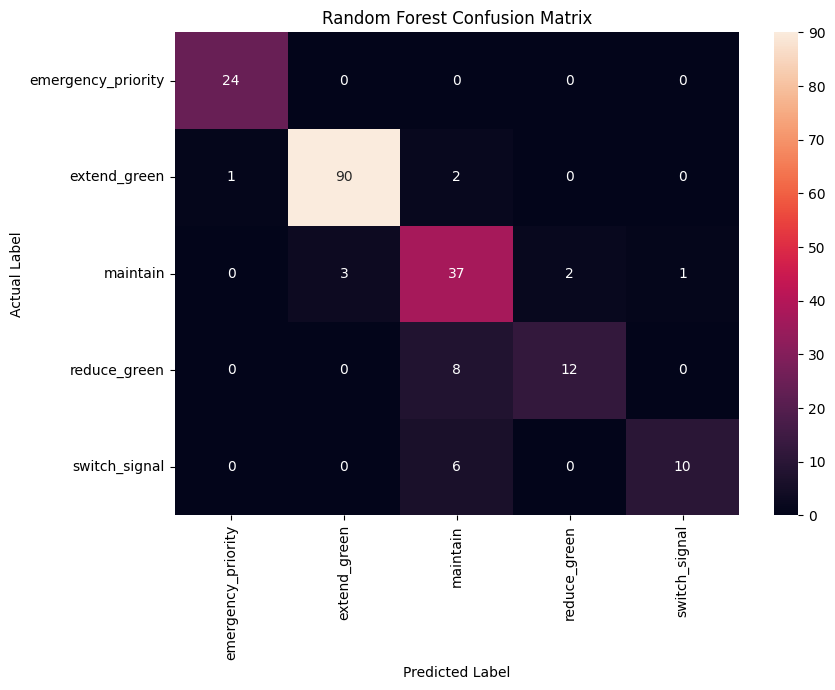


ERROR ANALYSIS
Total Test Samples      : 196
Correct Predictions     : 173
Misclassified Samples   : 23
Misclassification Rate  : 0.1173

MISCLASSIFIED RECORDS


,queue_length,waiting_time,emergency_vehicle,average_speed,current_signal_east,current_signal_north,current_signal_south,current_signal_west,traffic_density_high,traffic_density_low,traffic_density_medium,Actual,Predicted
776,-0.751586,-0.809608,0,0.842610,0,0,1,0,0,1,0,switch_signal,maintain
491,-0.961265,-1.120953,1,1.768133,0,1,0,0,0,1,0,extend_green,emergency_priority
500,-0.793522,-0.876325,0,1.269774,0,0,0,1,0,1,0,reduce_green,maintain
139,-0.583843,-0.275872,0,0.130668,0,0,0,1,0,0,1,maintain,extend_green
833,-0.835458,-0.898564,0,0.913804,0,1,0,0,0,1,0,maintain,reduce_green
348,-0.625778,-0.542740,0,0.557833,0,0,0,1,0,0,1,switch_signal,maintain
478,-0.416099,-0.476023,0,0.130668,0,1,0,0,0,0,1,extend_green,maintain
466,-0.877393,-0.809608,0,0.984998,0,0,1,0,0,1,0,switch_signal,maintain
578,-0.416099,-0.476023,0,0.415445,0,0,0,1,0,0,1,maintain,switch_signal
477,-0.919329,-0.831847,0,1.198580,0,0,0,1,0,1,0,reduce_green,maintain



Misclassification Summary:


Predicted,emergency_priority,extend_green,maintain,reduce_green,switch_signal
Actual,,,,,
extend_green,1,0,2,0,0
maintain,0,3,0,2,1
reduce_green,0,0,8,0,0
switch_signal,0,0,6,0,0



CLASS-WISE PERFORMANCE


,precision,recall,f1-score,support
emergency_priority,0.960000,1.000000,0.979592,24.000000
extend_green,0.967742,0.967742,0.967742,93.000000
maintain,0.698113,0.860465,0.770833,43.000000
reduce_green,0.857143,0.600000,0.705882,20.000000
switch_signal,0.909091,0.625000,0.740741,16.000000
accuracy,0.882653,0.882653,0.882653,0.882653
macro avg,0.878418,0.810641,0.832958,196.000000
weighted avg,0.891567,0.882653,0.880743,196.000000



TASK 6 COMPLETED SUCCESSFULLY

Models Trained:
1. Logistic Regression
2. Decision Tree
3. Random Forest

Evaluation:
✓ Accuracy
✓ Precision
✓ Recall
✓ F1-Score
✓ Classification Report
✓ Confusion Matrix

Error Analysis:
✓ Correct predictions
✓ Misclassified samples
✓ Misclassification rate
✓ Misclassification summary
✓ Class-wise performance



In [ ]:
# ============================================================
# CELBC710 – TASK 6
# Machine Learning Model Training, Evaluation & Error Analysis
# Smart Traffic Management System
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 1. Final Feature Matrix from Task 5
# ============================================================

print("Final Training Feature Matrix:")
display(X_train_selected.head())

print("\nTraining Shape:", X_train_selected.shape)
print("Testing Shape :", X_test_selected.shape)


# ============================================================
# 2. MODEL 1 – LOGISTIC REGRESSION
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_selected,
    y_train
)

y_pred_lr = logistic_model.predict(
    X_test_selected
)

print("\nLogistic Regression Training Completed!")


# ============================================================
# 3. MODEL 2 – DECISION TREE
# ============================================================

decision_tree = DecisionTreeClassifier(
    max_depth=6,
    random_state=42
)

decision_tree.fit(
    X_train_selected,
    y_train
)

y_pred_dt = decision_tree.predict(
    X_test_selected
)

print("Decision Tree Training Completed!")


# ============================================================
# 4. MODEL 3 – RANDOM FOREST
# ============================================================

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(
    X_train_selected,
    y_train
)

y_pred_rf = random_forest.predict(
    X_test_selected
)

print("Random Forest Training Completed!")


# ============================================================
# 5. MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    print("\n======================================")
    print(model_name)
    print("======================================")

    print("Accuracy  :", round(accuracy, 4))
    print("Precision :", round(precision, 4))
    print("Recall    :", round(recall, 4))
    print("F1-Score  :", round(f1, 4))

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    return [
        model_name,
        accuracy,
        precision,
        recall,
        f1
    ]


# ============================================================
# 6. EVALUATE ALL MODELS
# ============================================================

results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_lr
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf
    )
)


# ============================================================
# 7. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

print("\n======================================")
print("MODEL PERFORMANCE COMPARISON")
print("======================================")

display(results_df)


# ============================================================
# 8. MODEL PERFORMANCE GRAPH
# ============================================================

results_plot = results_df.set_index("Model")

results_plot[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 9. CONFUSION MATRIX – RANDOM FOREST
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred_rf
)

print("\n======================================")
print("RANDOM FOREST CONFUSION MATRIX")
print("======================================")

print(cm)


plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()


# ============================================================
# 10. ERROR / MISCLASSIFICATION ANALYSIS
# ============================================================

# Get original row indices from the test set
test_indices = X_test_selected.index


# Recover original records
error_analysis = clean_df.loc[
    test_indices
].copy()


# Add actual and predicted classes
error_analysis["Actual"] = label_encoder.inverse_transform(
    y_test
)

error_analysis["Predicted"] = label_encoder.inverse_transform(
    y_pred_rf
)


# Identify incorrect predictions
misclassified = error_analysis[
    error_analysis["Actual"] !=
    error_analysis["Predicted"]
]


# ============================================================
# 11. ERROR SUMMARY
# ============================================================

total_samples = len(y_test)

correct_predictions = np.sum(
    y_test == y_pred_rf
)

incorrect_predictions = np.sum(
    y_test != y_pred_rf
)


print("\n======================================")
print("ERROR ANALYSIS")
print("======================================")

print("Total Test Samples      :", total_samples)
print("Correct Predictions     :", correct_predictions)
print("Misclassified Samples   :", incorrect_predictions)

print(
    "Misclassification Rate  :",
    round(
        incorrect_predictions / total_samples,
        4
    )
)


# ============================================================
# 12. DISPLAY MISCLASSIFIED RECORDS
# ============================================================

print("\n======================================")
print("MISCLASSIFIED RECORDS")
print("======================================")


if len(misclassified) > 0:

    display(
        misclassified[
            [
                "queue_length",
                "waiting_time",
                "emergency_vehicle",
                "average_speed",
                "current_signal_east",
                "current_signal_north",
                "current_signal_south",
                "current_signal_west",
                "traffic_density_high",
                "traffic_density_low",
                "traffic_density_medium",
                "Actual",
                "Predicted"
            ]
        ]
    )

else:

    print("No misclassified records found.")


# ============================================================
# 13. MISCLASSIFICATION SUMMARY
# ============================================================

if len(misclassified) > 0:

    print("\nMisclassification Summary:")

    misclassification_summary = pd.crosstab(
        misclassified["Actual"],
        misclassified["Predicted"]
    )

    display(
        misclassification_summary
    )


# ============================================================
# 14. CLASS-WISE PERFORMANCE
# ============================================================

print("\n======================================")
print("CLASS-WISE PERFORMANCE")
print("======================================")

class_report = classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(
    class_report
).transpose()

display(class_report_df)


# ============================================================
# 15. FINAL TASK 6 OUTPUT
# ============================================================

print("\n======================================")
print("TASK 6 COMPLETED SUCCESSFULLY")
print("======================================")

print("""
Models Trained:
1. Logistic Regression
2. Decision Tree
3. Random Forest

Evaluation:
✓ Accuracy
✓ Precision
✓ Recall
✓ F1-Score
✓ Classification Report
✓ Confusion Matrix

Error Analysis:
✓ Correct predictions
✓ Misclassified samples
✓ Misclassification rate
✓ Misclassification summary
✓ Class-wise performance
""")

Training data shape: (782, 8)
Testing data shape : (196, 8)

Selected Features:
['waiting_time', 'queue_length', 'average_speed', 'traffic_density_low', 'emergency_vehicle', 'traffic_density_high', 'current_signal_east', 'traffic_density_medium']

LSTM Training Shape: (782, 1, 8)
LSTM Testing Shape : (196, 1, 8)

LSTM MODEL ARCHITECTURE


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,933 (81.77 KB)

 Trainable params: 20,933 (81.77 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING LSTM MODEL
Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5328 - loss: 1.5377 - val_accuracy: 0.6051 - val_loss: 1.4536
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6160 - loss: 1.3722 - val_accuracy: 0.6051 - val_loss: 1.2486
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6160 - loss: 1.1694 - val_accuracy: 0.6051 - val_loss: 1.0468
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6160 - loss: 1.0282 - val_accuracy: 0.6051 - val_loss: 0.9600
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6240 - loss: 0.9459 - val_accuracy: 0.6178 - val_loss: 0.9072
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6464 - loss: 0.8547 - val_accuracy: 0.6497 - val_loss: 0.8539
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6848 - loss: 0.8003 - val_accuracy: 0.6624 - val_loss: 0.8007
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7088 - loss: 0.7359 - val_accura

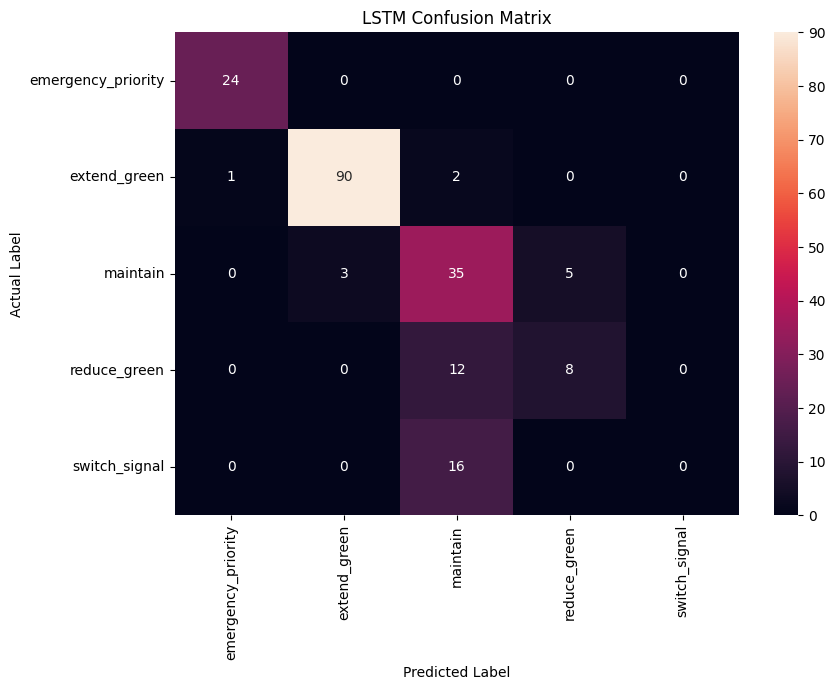

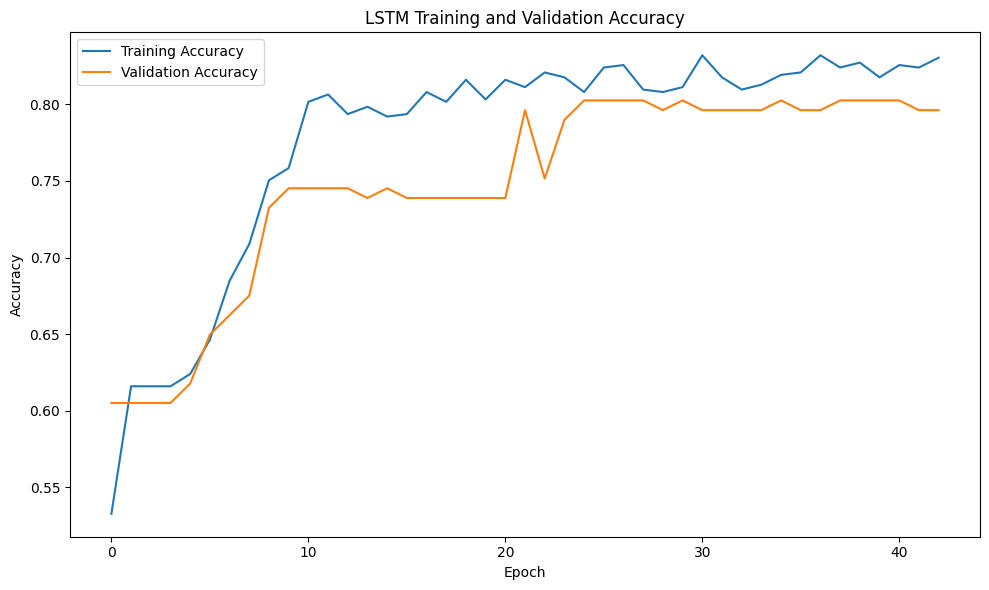

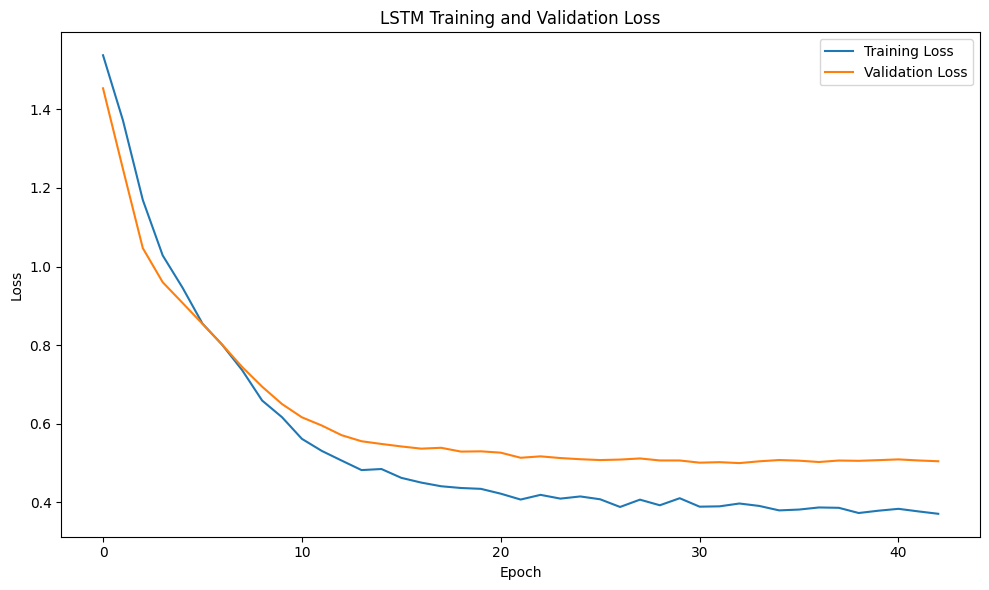


PREDICTION COMPARISON


,Actual,Predicted
0,extend_green,extend_green
1,extend_green,extend_green
2,extend_green,extend_green
3,switch_signal,maintain
4,extend_green,extend_green
5,extend_green,extend_green
6,maintain,maintain
7,extend_green,extend_green
8,reduce_green,reduce_green
9,extend_green,extend_green



PREDICTION ANALYSIS
Total Test Samples     : 196
Correct Predictions    : 157
Incorrect Predictions  : 39
Misclassification Rate : 0.199

TASK 7 COMPLETED SUCCESSFULLY

Deep Learning Architecture:
✓ LSTM Neural Network

Model Components:
✓ LSTM Layer – 64 units
✓ Dropout – 30%
✓ Dense Layer – 32 neurons
✓ Dropout – 20%
✓ Softmax Output Layer

Training:
✓ Adam Optimizer
✓ Learning Rate = 0.001
✓ Batch Size = 32
✓ Maximum Epochs = 50
✓ Early Stopping
✓ Validation Split = 20%

Evaluation:
✓ Test Accuracy
✓ Test Loss
✓ Classification Report
✓ Confusion Matrix
✓ Training/Validation Accuracy
✓ Training/Validation Loss
✓ Prediction Analysis



In [ ]:
# ============================================================
# CELBC710 – TASK 7
# Deep Representation & Learning Systems
# Smart Traffic Management System
# LSTM-Based Traffic Action Prediction
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 1. CHECK DATA FROM TASK 5
# ============================================================

print("Training data shape:", X_train_selected.shape)
print("Testing data shape :", X_test_selected.shape)

print("\nSelected Features:")
print(list(X_train_selected.columns))


# ============================================================
# 2. CONVERT DATA INTO LSTM FORMAT
# ============================================================
# LSTM expects:
# [samples, timesteps, features]
#
# Here each traffic record is treated as
# one timestep containing multiple traffic features.

X_train_lstm = X_train_selected.values.reshape(
    X_train_selected.shape[0],
    1,
    X_train_selected.shape[1]
)

X_test_lstm = X_test_selected.values.reshape(
    X_test_selected.shape[0],
    1,
    X_test_selected.shape[1]
)


print("\nLSTM Training Shape:", X_train_lstm.shape)
print("LSTM Testing Shape :", X_test_lstm.shape)


# ============================================================
# 3. BUILD LSTM MODEL
# ============================================================

lstm_model = Sequential([

    # LSTM Layer
    LSTM(
        64,
        input_shape=(
            X_train_lstm.shape[1],
            X_train_lstm.shape[2]
        ),
        return_sequences=False
    ),

    # Regularization
    Dropout(0.3),

    # Dense hidden layer
    Dense(
        32,
        activation="relu"
    ),

    # Additional regularization
    Dropout(0.2),

    # Output layer
    Dense(
        len(label_encoder.classes_),
        activation="softmax"
    )
])


# ============================================================
# 4. COMPILE MODEL
# ============================================================

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 5. DISPLAY MODEL ARCHITECTURE
# ============================================================

print("\n======================================")
print("LSTM MODEL ARCHITECTURE")
print("======================================")

lstm_model.summary()


# ============================================================
# 6. EARLY STOPPING
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


# ============================================================
# 7. TRAIN LSTM MODEL
# ============================================================

print("\n======================================")
print("TRAINING LSTM MODEL")
print("======================================")

history = lstm_model.fit(
    X_train_lstm,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)


print("\nLSTM Training Completed!")


# ============================================================
# 8. MODEL EVALUATION
# ============================================================

test_loss, test_accuracy = lstm_model.evaluate(
    X_test_lstm,
    y_test,
    verbose=0
)


print("\n======================================")
print("LSTM MODEL EVALUATION")
print("======================================")

print("Test Loss     :", round(test_loss, 4))
print("Test Accuracy :", round(test_accuracy, 4))


# ============================================================
# 9. PREDICTIONS
# ============================================================

y_pred_probability = lstm_model.predict(
    X_test_lstm,
    verbose=0
)

y_pred_lstm = np.argmax(
    y_pred_probability,
    axis=1
)


# ============================================================
# 10. CLASSIFICATION REPORT
# ============================================================

print("\n======================================")
print("CLASSIFICATION REPORT")
print("======================================")

print(
    classification_report(
        y_test,
        y_pred_lstm,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

cm_lstm = confusion_matrix(
    y_test,
    y_pred_lstm
)


print("\n======================================")
print("CONFUSION MATRIX")
print("======================================")

print(cm_lstm)


plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Confusion Matrix")

plt.tight_layout()
plt.show()


# ============================================================
# 12. TRAINING & VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 13. TRAINING & VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 14. PREDICTION COMPARISON
# ============================================================

actual_labels = label_encoder.inverse_transform(
    y_test
)

predicted_labels = label_encoder.inverse_transform(
    y_pred_lstm
)


prediction_comparison = pd.DataFrame({

    "Actual": actual_labels,

    "Predicted": predicted_labels

})


print("\n======================================")
print("PREDICTION COMPARISON")
print("======================================")

display(
    prediction_comparison.head(20)
)


# ============================================================
# 15. CORRECT / INCORRECT PREDICTIONS
# ============================================================

correct_predictions = np.sum(
    y_test == y_pred_lstm
)

incorrect_predictions = np.sum(
    y_test != y_pred_lstm
)

total_predictions = len(y_test)


print("\n======================================")
print("PREDICTION ANALYSIS")
print("======================================")

print(
    "Total Test Samples     :",
    total_predictions
)

print(
    "Correct Predictions    :",
    correct_predictions
)

print(
    "Incorrect Predictions  :",
    incorrect_predictions
)

print(
    "Misclassification Rate :",
    round(
        incorrect_predictions / total_predictions,
        4
    )
)


# ============================================================
# 16. FINAL TASK 7 SUMMARY
# ============================================================

print("\n======================================")
print("TASK 7 COMPLETED SUCCESSFULLY")
print("======================================")

print("""
Deep Learning Architecture:
✓ LSTM Neural Network

Model Components:
✓ LSTM Layer – 64 units
✓ Dropout – 30%
✓ Dense Layer – 32 neurons
✓ Dropout – 20%
✓ Softmax Output Layer

Training:
✓ Adam Optimizer
✓ Learning Rate = 0.001
✓ Batch Size = 32
✓ Maximum Epochs = 50
✓ Early Stopping
✓ Validation Split = 20%

Evaluation:
✓ Test Accuracy
✓ Test Loss
✓ Classification Report
✓ Confusion Matrix
✓ Training/Validation Accuracy
✓ Training/Validation Loss
✓ Prediction Analysis
""")


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.882653,0.891567,0.882653,0.880743
1,LSTM,0.801020,0.757661,0.801020,0.770804


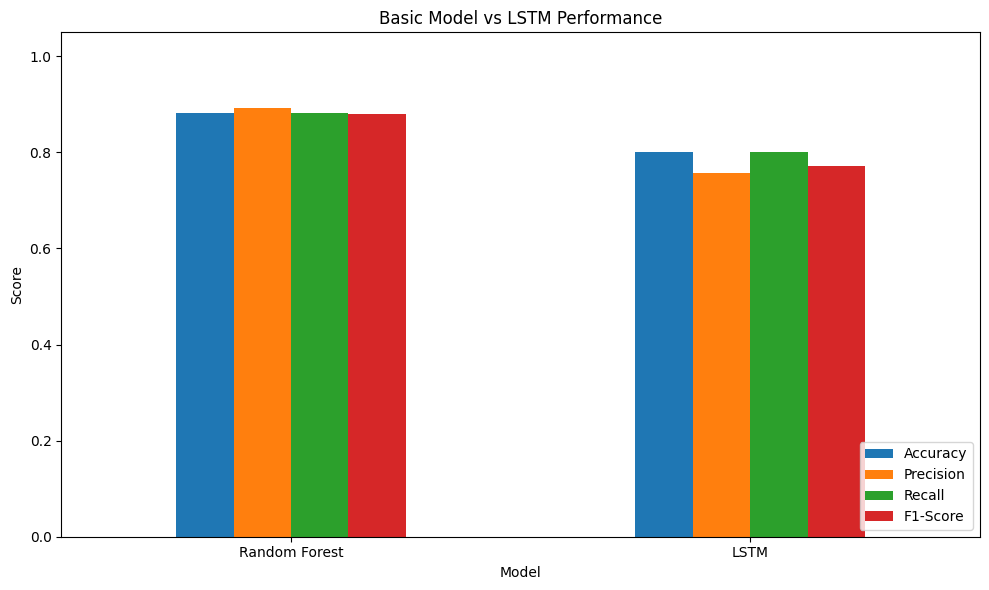


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
1,queue_length,0.249262
0,waiting_time,0.244719
4,emergency_vehicle,0.213626
2,average_speed,0.193794
6,current_signal_east,0.038792
3,traffic_density_low,0.033023
5,traffic_density_high,0.014541
7,traffic_density_medium,0.012244


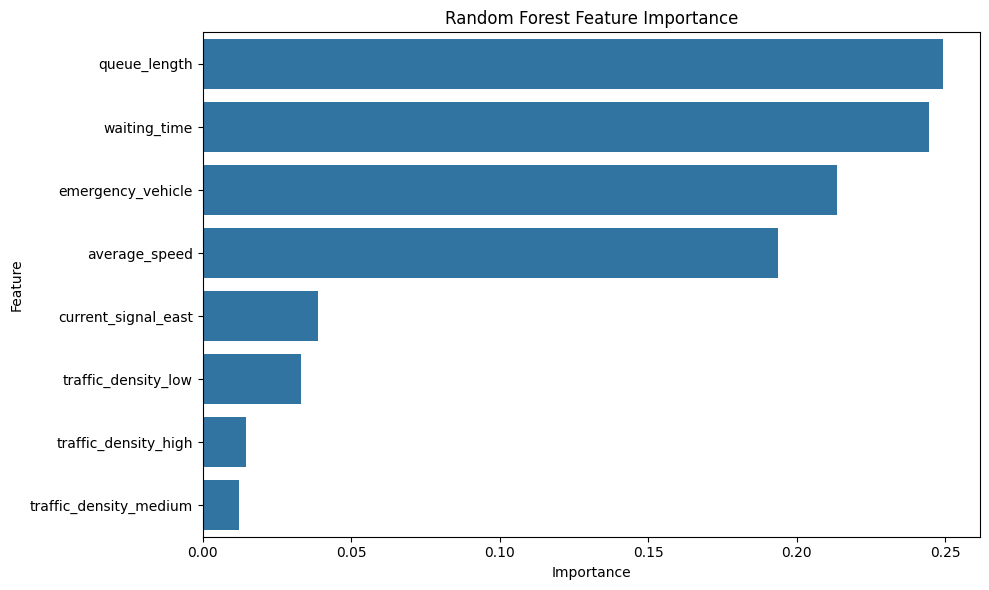


LSTM FEATURE IMPORTANCE


,Feature,Importance
4,emergency_vehicle,0.194898
2,average_speed,0.077551
0,waiting_time,0.061224
1,queue_length,0.046939
6,current_signal_east,0.024490
7,traffic_density_medium,0.023469
5,traffic_density_high,0.007143
3,traffic_density_low,0.001020


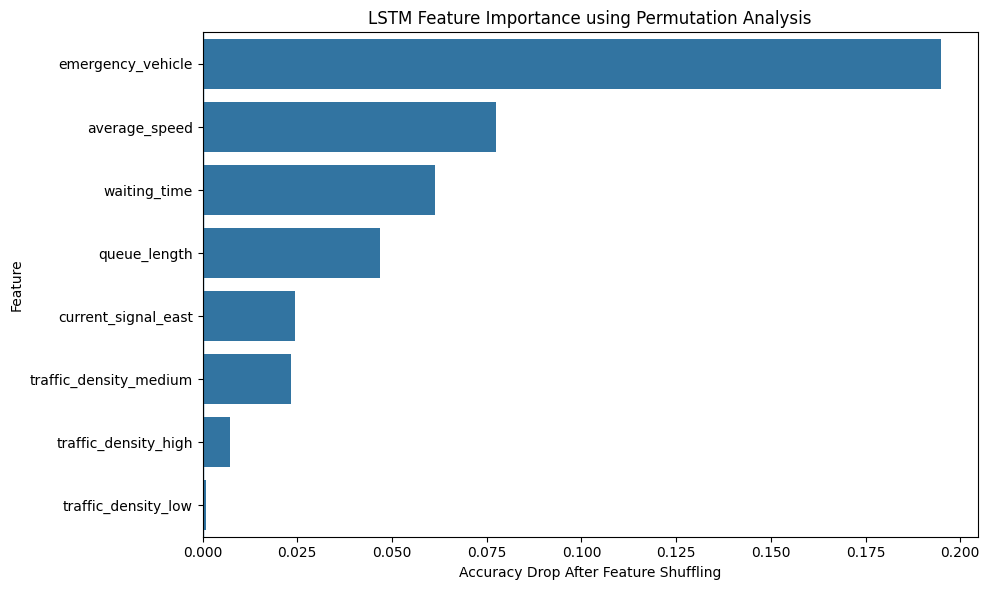


INTERPRETABILITY COMPARISON


,Feature,Random Forest Importance,LSTM Importance
2,emergency_vehicle,0.213626,0.194898
3,average_speed,0.193794,0.077551
1,waiting_time,0.244719,0.061224
0,queue_length,0.249262,0.046939
4,current_signal_east,0.038792,0.024490
7,traffic_density_medium,0.012244,0.023469
6,traffic_density_high,0.014541,0.007143
5,traffic_density_low,0.033023,0.001020



LSTM PREDICTION CONFIDENCE


,Actual,Predicted,Confidence
0,extend_green,extend_green,0.999631
1,extend_green,extend_green,0.999192
2,extend_green,extend_green,0.999832
3,switch_signal,maintain,0.654841
4,extend_green,extend_green,0.999993
5,extend_green,extend_green,0.999556
6,maintain,maintain,0.666386
7,extend_green,extend_green,0.999854
8,reduce_green,reduce_green,0.540799
9,extend_green,extend_green,0.998933


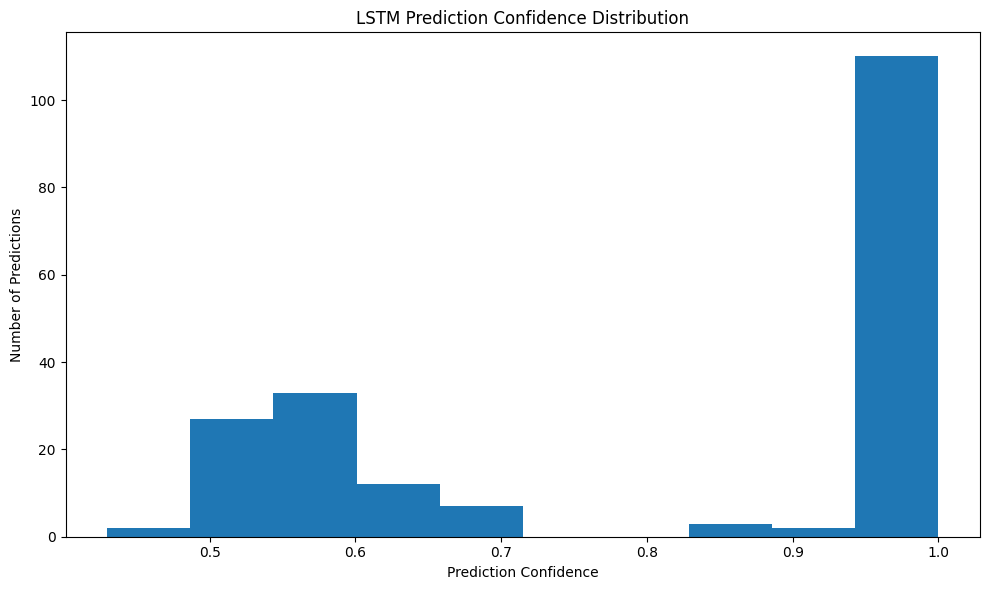

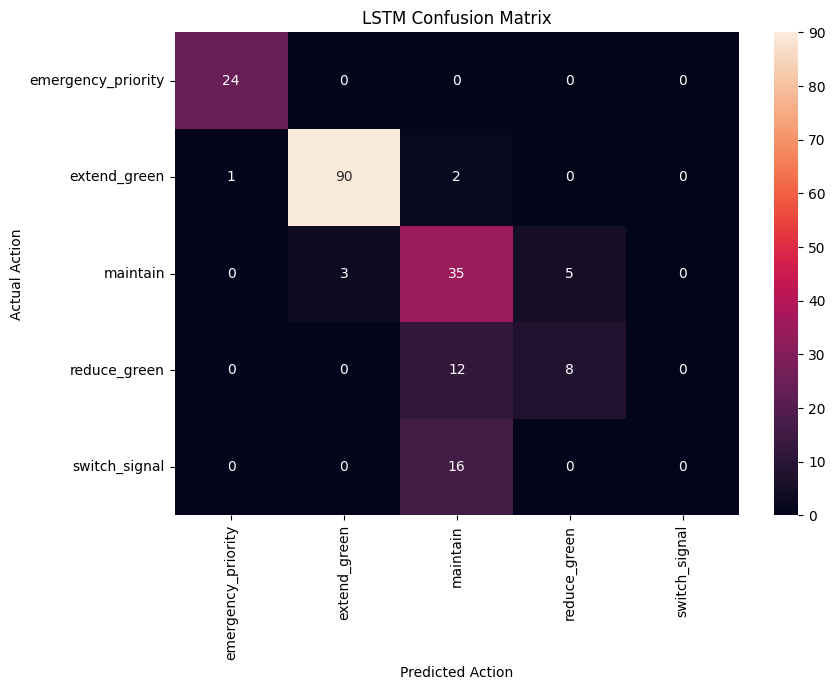


LSTM MISCLASSIFICATION ANALYSIS
Total Test Samples : 196
Correct Predictions: 157
Incorrect Predictions: 39
Misclassification Rate: 0.199

Misclassified Predictions:


,Actual,Predicted,Confidence
3,switch_signal,maintain,0.654841
17,switch_signal,maintain,0.524869
30,switch_signal,maintain,0.507783
31,switch_signal,maintain,0.495253
39,extend_green,emergency_priority,0.993206
42,reduce_green,maintain,0.555707
45,switch_signal,maintain,0.477324
52,switch_signal,maintain,0.650745
57,switch_signal,maintain,0.660838
59,maintain,extend_green,0.500677



FINAL MODEL COMPARISON
Random Forest achieved higher test accuracy than LSTM.

Random Forest Accuracy: 0.8827
LSTM Accuracy: 0.801

TASK 8 COMPLETED SUCCESSFULLY

Interpretability Techniques:
✓ Random Forest Feature Importance
✓ LSTM Permutation Feature Importance
✓ Prediction Confidence Analysis

Visualizations:
✓ Model Performance Comparison
✓ Feature Importance Graph
✓ LSTM Feature Importance
✓ Confidence Distribution
✓ LSTM Confusion Matrix

Comparison:
✓ Random Forest vs LSTM
✓ Accuracy
✓ Precision
✓ Recall
✓ F1-Score
✓ Interpretability

The important traffic features influencing
the model predictions were identified and
the reliability of LSTM predictions was
analyzed using prediction confidence.



In [ ]:
# ============================================================
# CELBC710 – TASK 8
# Interpretability, Visualization & Model Comparison
# Smart Traffic Management System
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# 1. LSTM PREDICTIONS
# ============================================================

# Predict probabilities
lstm_probabilities = lstm_model.predict(
    X_test_lstm,
    verbose=0
)

# Convert probabilities to class labels
y_pred_lstm = np.argmax(
    lstm_probabilities,
    axis=1
)


# ============================================================
# 2. BASIC MODEL – RANDOM FOREST FROM TASK 6
# ============================================================

# Random Forest prediction
y_pred_rf = random_forest.predict(
    X_test_selected
)


# ============================================================
# 3. PERFORMANCE COMPARISON
# ============================================================

models = [
    "Random Forest",
    "LSTM"
]

accuracy_values = [
    accuracy_score(y_test, y_pred_rf),
    accuracy_score(y_test, y_pred_lstm)
]

precision_values = [
    precision_score(
        y_test,
        y_pred_rf,
        average="weighted",
        zero_division=0
    ),

    precision_score(
        y_test,
        y_pred_lstm,
        average="weighted",
        zero_division=0
    )
]

recall_values = [
    recall_score(
        y_test,
        y_pred_rf,
        average="weighted",
        zero_division=0
    ),

    recall_score(
        y_test,
        y_pred_lstm,
        average="weighted",
        zero_division=0
    )
]

f1_values = [
    f1_score(
        y_test,
        y_pred_rf,
        average="weighted",
        zero_division=0
    ),

    f1_score(
        y_test,
        y_pred_lstm,
        average="weighted",
        zero_division=0
    )
]


comparison_df = pd.DataFrame({

    "Model": models,

    "Accuracy": accuracy_values,

    "Precision": precision_values,

    "Recall": recall_values,

    "F1-Score": f1_values

})


print("\n======================================")
print("MODEL PERFORMANCE COMPARISON")
print("======================================")

display(comparison_df)


# ============================================================
# 4. PERFORMANCE VISUALIZATION
# ============================================================

comparison_plot = comparison_df.set_index(
    "Model"
)

comparison_plot[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Basic Model vs LSTM Performance"
)

plt.ylabel("Score")

plt.ylim(
    0,
    1.05
)

plt.xticks(
    rotation=0
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_importance = pd.DataFrame({

    "Feature":
        X_train_selected.columns,

    "Importance":
        random_forest.feature_importances_

})

rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)


print("\n======================================")
print("RANDOM FOREST FEATURE IMPORTANCE")
print("======================================")

display(
    rf_importance
)


# ============================================================
# 6. RANDOM FOREST FEATURE IMPORTANCE GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. LSTM FEATURE INTERPRETABILITY
# ============================================================
# Permutation importance:
# Shuffle one feature at a time and observe
# how much the LSTM prediction performance changes.
#
# Since LSTM requires 3D input, we create a custom
# scoring function for permutation analysis.


baseline_accuracy = accuracy_score(
    y_test,
    y_pred_lstm
)


lstm_feature_importance = []


for feature_index, feature_name in enumerate(
    X_test_selected.columns
):

    accuracy_drop_values = []

    X_permuted = X_test_lstm.copy()

    for repeat in range(5):

        X_temp = X_permuted.copy()

        shuffled_values = X_temp[
            :,
            0,
            feature_index
        ].copy()

        np.random.shuffle(
            shuffled_values
        )

        X_temp[
            :,
            0,
            feature_index
        ] = shuffled_values

        predictions = np.argmax(
            lstm_model.predict(
                X_temp,
                verbose=0
            ),
            axis=1
        )

        shuffled_accuracy = accuracy_score(
            y_test,
            predictions
        )

        accuracy_drop_values.append(
            baseline_accuracy -
            shuffled_accuracy
        )

    mean_drop = np.mean(
        accuracy_drop_values
    )

    lstm_feature_importance.append(
        mean_drop
    )


lstm_importance_df = pd.DataFrame({

    "Feature":
        X_test_selected.columns,

    "Importance":
        lstm_feature_importance

})


lstm_importance_df = lstm_importance_df.sort_values(
    "Importance",
    ascending=False
)


print("\n======================================")
print("LSTM FEATURE IMPORTANCE")
print("======================================")

display(
    lstm_importance_df
)


# ============================================================
# 8. LSTM FEATURE IMPORTANCE VISUALIZATION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

sns.barplot(
    data=lstm_importance_df,
    x="Importance",
    y="Feature"
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "LSTM Feature Importance using Permutation Analysis"
)

plt.xlabel(
    "Accuracy Drop After Feature Shuffling"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()
plt.show()


# ============================================================
# 9. RANDOM FOREST vs LSTM INTERPRETABILITY
# ============================================================

interpretability_df = pd.merge(

    rf_importance.rename(
        columns={
            "Importance":
            "Random Forest Importance"
        }
    ),

    lstm_importance_df.rename(
        columns={
            "Importance":
            "LSTM Importance"
        }
    ),

    on="Feature"

)


print("\n======================================")
print("INTERPRETABILITY COMPARISON")
print("======================================")

display(
    interpretability_df.sort_values(
        "LSTM Importance",
        ascending=False
    )
)


# ============================================================
# 10. LSTM CONFIDENCE ANALYSIS
# ============================================================

prediction_confidence = np.max(
    lstm_probabilities,
    axis=1
)


confidence_df = pd.DataFrame({

    "Actual":
        label_encoder.inverse_transform(
            y_test
        ),

    "Predicted":
        label_encoder.inverse_transform(
            y_pred_lstm
        ),

    "Confidence":
        prediction_confidence

})


print("\n======================================")
print("LSTM PREDICTION CONFIDENCE")
print("======================================")

display(
    confidence_df.head(20)
)


# ============================================================
# 11. CONFIDENCE DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    prediction_confidence,
    bins=10
)

plt.title(
    "LSTM Prediction Confidence Distribution"
)

plt.xlabel(
    "Prediction Confidence"
)

plt.ylabel(
    "Number of Predictions"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. LSTM CONFUSION MATRIX
# ============================================================

cm_lstm = confusion_matrix(
    y_test,
    y_pred_lstm
)


plt.figure(
    figsize=(9, 7)
)

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel(
    "Predicted Action"
)

plt.ylabel(
    "Actual Action"
)

plt.title(
    "LSTM Confusion Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# 13. MISCLASSIFICATION ANALYSIS
# ============================================================

misclassified_lstm = confidence_df[
    confidence_df["Actual"] !=
    confidence_df["Predicted"]
].copy()


print("\n======================================")
print("LSTM MISCLASSIFICATION ANALYSIS")
print("======================================")

print(
    "Total Test Samples :",
    len(y_test)
)

print(
    "Correct Predictions:",
    np.sum(y_test == y_pred_lstm)
)

print(
    "Incorrect Predictions:",
    np.sum(y_test != y_pred_lstm)
)

print(
    "Misclassification Rate:",
    round(
        np.mean(y_test != y_pred_lstm),
        4
    )
)


print("\nMisclassified Predictions:")

display(
    misclassified_lstm.head(20)
)


# ============================================================
# 14. FINAL COMPARISON
# ============================================================

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

lstm_accuracy = accuracy_score(
    y_test,
    y_pred_lstm
)


print("\n======================================")
print("FINAL MODEL COMPARISON")
print("======================================")

if lstm_accuracy > rf_accuracy:

    print(
        "LSTM achieved higher test accuracy "
        "than Random Forest."
    )

elif lstm_accuracy < rf_accuracy:

    print(
        "Random Forest achieved higher test accuracy "
        "than LSTM."
    )

else:

    print(
        "Both models achieved the same test accuracy."
    )


print("\nRandom Forest Accuracy:",
      round(rf_accuracy, 4))

print("LSTM Accuracy:",
      round(lstm_accuracy, 4))


# ============================================================
# 15. TASK 8 CONCLUSION
# ============================================================

print("\n======================================")
print("TASK 8 COMPLETED SUCCESSFULLY")
print("======================================")

print("""
Interpretability Techniques:
✓ Random Forest Feature Importance
✓ LSTM Permutation Feature Importance
✓ Prediction Confidence Analysis

Visualizations:
✓ Model Performance Comparison
✓ Feature Importance Graph
✓ LSTM Feature Importance
✓ Confidence Distribution
✓ LSTM Confusion Matrix

Comparison:
✓ Random Forest vs LSTM
✓ Accuracy
✓ Precision
✓ Recall
✓ F1-Score
✓ Interpretability

The important traffic features influencing
the model predictions were identified and
the reliability of LSTM predictions was
analyzed using prediction confidence.
""")

In [ ]:

# ============================================================
# CELBC710 - TASK 9
# Integrated Intelligent System
# Smart Traffic Management System
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# 1. Check that required models and variables exist
required = [
    "clean_df", "X_train_selected", "X_test_selected",
    "y_train", "y_test", "label_encoder",
    "random_forest", "lstm_model",
    "X_test_lstm"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        f"Run the required previous tasks first. Missing: {missing}"
    )

# 2. AI reasoning rules
def ai_decision(
    traffic_input,
    lstm_probabilities,
    rf_prediction,
    confidence_threshold=0.60
):
    classes = list(label_encoder.classes_)
    lstm_index = int(np.argmax(lstm_probabilities))
    lstm_action = classes[lstm_index]
    lstm_confidence = float(np.max(lstm_probabilities))
    rf_action = classes[int(rf_prediction)]

    # Safety rule: emergency vehicle gets priority.
    if int(traffic_input["emergency_vehicle"]) == 1:
        final_action = "emergency_priority"
        reason = "Emergency vehicle detected; emergency priority rule applied."

    elif lstm_confidence < confidence_threshold:
        # Use the trained Random Forest prediction when
        # the LSTM is uncertain.
        final_action = rf_action
        reason = "LSTM confidence is low; Random Forest fallback used."

    elif lstm_action == rf_action:
        final_action = lstm_action
        reason = "LSTM and Random Forest predictions agree."

    else:
        # Explicit conflict policy for this prototype.
        final_action = rf_action
        reason = "Models disagree; Random Forest fallback policy applied."

    return {
        "LSTM_Prediction": lstm_action,
        "LSTM_Confidence": round(lstm_confidence, 4),
        "Random_Forest_Prediction": rf_action,
        "Final_AI_Decision": final_action,
        "Reason": reason
    }


# 3. Integrate the existing test set
# X_test_selected is already in the required feature format.
lstm_probabilities = lstm_model.predict(
    X_test_lstm, verbose=0
)
rf_predictions = random_forest.predict(X_test_selected)

# 4. Demonstrate the integrated system on representative inputs
def run_system(row_position):
    features = X_test_selected.iloc[[row_position]]
    lstm_input = X_test_lstm[row_position:row_position + 1]

    traffic_input = features.iloc[0].to_dict()

    result = ai_decision(
        traffic_input,
        lstm_probabilities[row_position],
        rf_predictions[row_position]
    )

    result["Test_Row"] = row_position
    return result

demo_results = pd.DataFrame([
    run_system(i) for i in range(min(10, len(X_test_selected)))
])

print("INTEGRATED INTELLIGENT SYSTEM")
display(demo_results)

# 5. System-level validation
# The final action is compared with the true label.
# Note: emergency override changes the decision by design.
y_true_labels = label_encoder.inverse_transform(y_test)
y_final_labels = demo_results["Final_AI_Decision"].tolist()

print("\nSample end-to-end decisions:")
display(pd.DataFrame({
    "Actual_Action": y_true_labels[:len(y_final_labels)],
    "System_Decision": y_final_labels
}))

print("\nTask 9 pipeline completed.")
print("Components: LSTM + Random Forest + AI rule engine")


INTEGRATED INTELLIGENT SYSTEM


,LSTM_Prediction,LSTM_Confidence,Random_Forest_Prediction,Final_AI_Decision,Reason,Test_Row
0,extend_green,0.9996,extend_green,extend_green,LSTM and Random Forest predictions agree.,0
1,extend_green,0.9992,extend_green,extend_green,LSTM and Random Forest predictions agree.,1
2,extend_green,0.9998,extend_green,extend_green,LSTM and Random Forest predictions agree.,2
3,maintain,0.6548,switch_signal,switch_signal,Models disagree; Random Forest fallback policy...,3
4,extend_green,1.0000,extend_green,extend_green,LSTM and Random Forest predictions agree.,4
5,extend_green,0.9996,extend_green,extend_green,LSTM and Random Forest predictions agree.,5
6,maintain,0.6664,maintain,maintain,LSTM and Random Forest predictions agree.,6
7,extend_green,0.9999,extend_green,extend_green,LSTM and Random Forest predictions agree.,7
8,reduce_green,0.5408,reduce_green,reduce_green,LSTM confidence is low; Random Forest fallback...,8
9,extend_green,0.9989,extend_green,extend_green,LSTM and Random Forest predictions agree.,9



Sample end-to-end decisions:


,Actual_Action,System_Decision
0,extend_green,extend_green
1,extend_green,extend_green
2,extend_green,extend_green
3,switch_signal,switch_signal
4,extend_green,extend_green
5,extend_green,extend_green
6,maintain,maintain
7,extend_green,extend_green
8,reduce_green,reduce_green
9,extend_green,extend_green



Task 9 pipeline completed.
Components: LSTM + Random Forest + AI rule engine


SYSTEM PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,LSTM,0.801020,0.757661,0.801020,0.770804
1,Random Forest,0.882653,0.891567,0.882653,0.880743
2,Integrated AI System,0.882653,0.891567,0.882653,0.880743


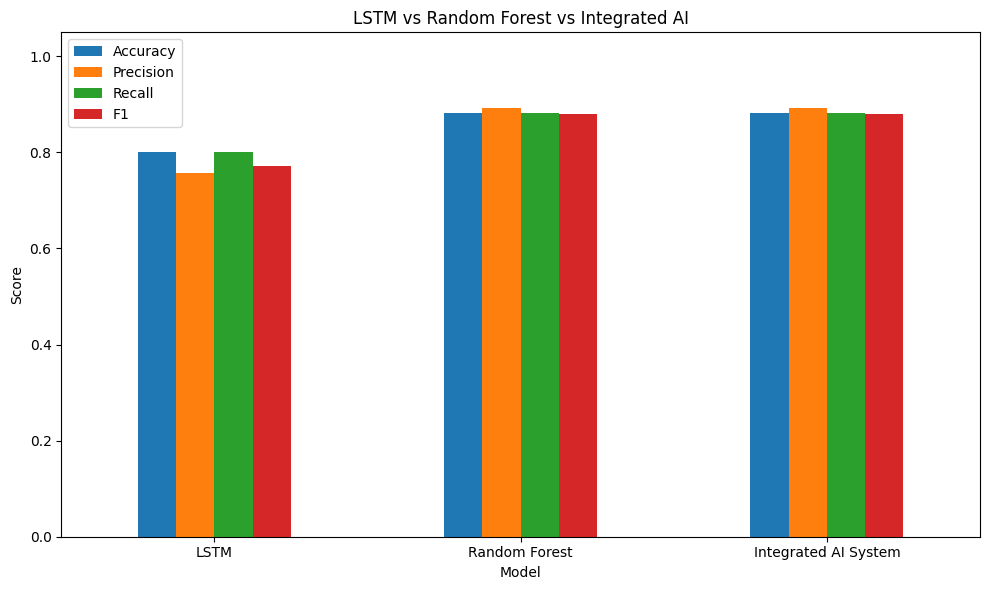

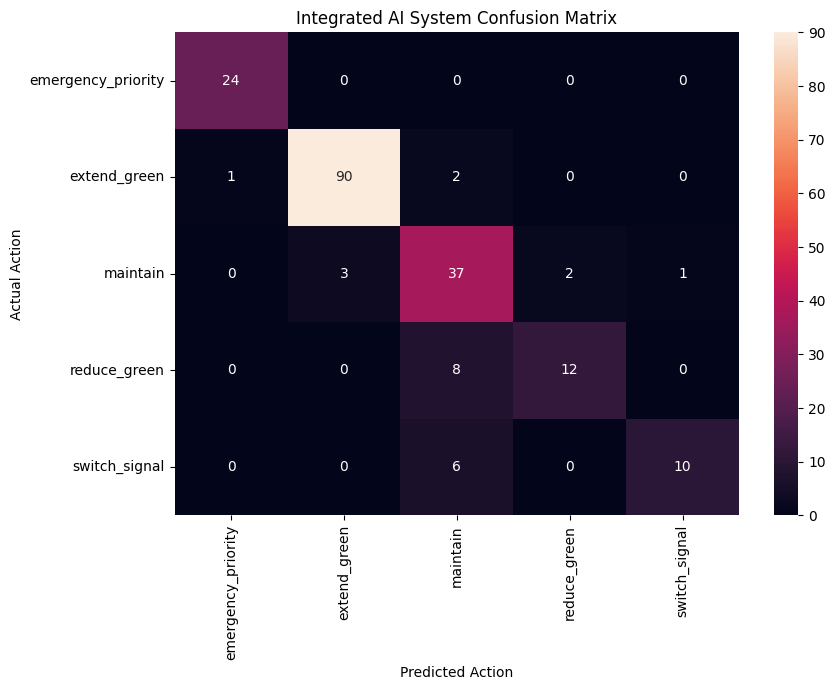


Integrated System Classification Report
                    precision    recall  f1-score   support

emergency_priority       0.96      1.00      0.98        24
      extend_green       0.97      0.97      0.97        93
          maintain       0.70      0.86      0.77        43
      reduce_green       0.86      0.60      0.71        20
     switch_signal       0.91      0.62      0.74        16

          accuracy                           0.88       196
         macro avg       0.88      0.81      0.83       196
      weighted avg       0.89      0.88      0.88       196


Random Forest Feature Importance


,Feature,Importance
1,queue_length,0.249262
0,waiting_time,0.244719
4,emergency_vehicle,0.213626
2,average_speed,0.193794
6,current_signal_east,0.038792
3,traffic_density_low,0.033023
5,traffic_density_high,0.014541
7,traffic_density_medium,0.012244


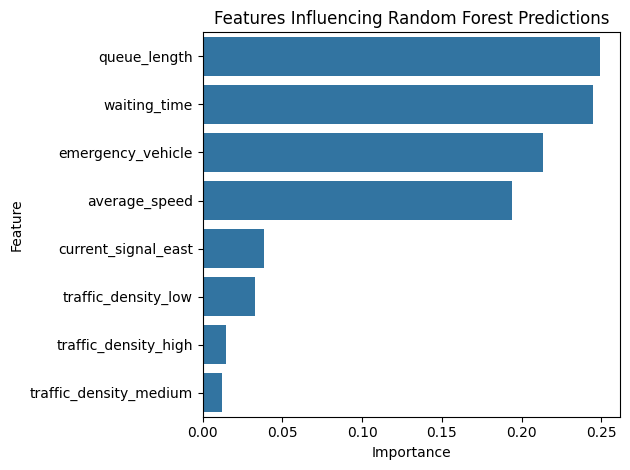


Decision explanations (first 20 rows)


,Actual_Action,LSTM_Prediction,LSTM_Confidence,Random_Forest_Prediction,Final_AI_Decision,Reason,Correct
0,extend_green,extend_green,0.9996,extend_green,extend_green,LSTM and Random Forest predictions agree.,True
1,extend_green,extend_green,0.9992,extend_green,extend_green,LSTM and Random Forest predictions agree.,True
2,extend_green,extend_green,0.9998,extend_green,extend_green,LSTM and Random Forest predictions agree.,True
3,switch_signal,maintain,0.6548,switch_signal,switch_signal,Models disagree; Random Forest fallback policy...,True
4,extend_green,extend_green,1.0000,extend_green,extend_green,LSTM and Random Forest predictions agree.,True
5,extend_green,extend_green,0.9996,extend_green,extend_green,LSTM and Random Forest predictions agree.,True
6,maintain,maintain,0.6664,maintain,maintain,LSTM and Random Forest predictions agree.,True
7,extend_green,extend_green,0.9999,extend_green,extend_green,LSTM and Random Forest predictions agree.,True
8,reduce_green,reduce_green,0.5408,reduce_green,reduce_green,LSTM confidence is low; Random Forest fallback...,True
9,extend_green,extend_green,0.9989,extend_green,extend_green,LSTM and Random Forest predictions agree.,True



SYSTEM VALIDATION
Test records: 196
Correct decisions: 173
Incorrect decisions: 23
Model agreement rate: 0.8673
Low-confidence LSTM rate: 0.3163
Emergency override count: 25

ETHICAL AND FAIRNESS REVIEW

1. Safety:
   Incorrect signal decisions can cause congestion or accidents.
   Real deployment requires fail-safe controls and expert approval.

2. Emergency priority:
   Emergency overrides must be tested against traffic regulations
   and safe signal-transition constraints.

3. Bias:
   Traffic patterns may differ across roads, times and neighborhoods.
   Evaluate performance by location and time when such labels exist.

4. Data quality:
   Missing, stale or inaccurate sensor readings can produce wrong actions.

5. Explainability:
   The rule engine records its decision reason. Random Forest feature
   importance is global and does not prove the cause of an individual
   prediction.

6. Privacy and governance:
   Minimize retained sensor data, control access, and document decisions.

In [ ]:

# ============================================================
# CELBC710 - TASK 10
# System Validation, Explainability and Responsible AI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Generate predictions on the complete held-out test set
lstm_probabilities = lstm_model.predict(
    X_test_lstm, verbose=0
)
rf_predictions = random_forest.predict(X_test_selected)

# 2. Apply the integrated AI decision engine to every test row
system_results = []

for i in range(len(X_test_selected)):
    traffic_input = X_test_selected.iloc[i].to_dict()

    decision = ai_decision(
        traffic_input,
        lstm_probabilities[i],
        rf_predictions[i]
    )
    system_results.append(decision)

system_df = pd.DataFrame(system_results)

y_system = label_encoder.transform(
    system_df["Final_AI_Decision"]
)
y_lstm = np.argmax(lstm_probabilities, axis=1)
y_rf = rf_predictions

# 3. Compare performance
comparison = pd.DataFrame([
    {
        "Model": "LSTM",
        "Accuracy": accuracy_score(y_test, y_lstm),
        "Precision": precision_score(
            y_test, y_lstm, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_lstm, average="weighted", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_lstm, average="weighted", zero_division=0
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_rf),
        "Precision": precision_score(
            y_test, y_rf, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_rf, average="weighted", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_rf, average="weighted", zero_division=0
        )
    },
    {
        "Model": "Integrated AI System",
        "Accuracy": accuracy_score(y_test, y_system),
        "Precision": precision_score(
            y_test, y_system, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_system, average="weighted", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_system, average="weighted", zero_division=0
        )
    }
])

print("SYSTEM PERFORMANCE COMPARISON")
display(comparison)

comparison.set_index("Model").plot(
    kind="bar", figsize=(10, 6), ylim=(0, 1.05)
)
plt.title("LSTM vs Random Forest vs Integrated AI")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Integrated system confusion matrix
cm = confusion_matrix(
    y_test,
    y_system,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Integrated AI System Confusion Matrix")
plt.xlabel("Predicted Action")
plt.ylabel("Actual Action")
plt.tight_layout()
plt.show()

print("\nIntegrated System Classification Report")
print(classification_report(
    y_test,
    y_system,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# 5. Explainability: show important Random Forest features
rf_importance = pd.DataFrame({
    "Feature": X_train_selected.columns,
    "Importance": random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nRandom Forest Feature Importance")
display(rf_importance)

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)
plt.title("Features Influencing Random Forest Predictions")
plt.tight_layout()
plt.show()

# 6. Decision explanations and confidence
system_df["Actual_Action"] = label_encoder.inverse_transform(y_test)
system_df["Correct"] = (
    system_df["Actual_Action"] == system_df["Final_AI_Decision"]
)

print("\nDecision explanations (first 20 rows)")
display(system_df[[
    "Actual_Action",
    "LSTM_Prediction",
    "LSTM_Confidence",
    "Random_Forest_Prediction",
    "Final_AI_Decision",
    "Reason",
    "Correct"
]].head(20))

# 7. Basic system reliability checks
print("\nSYSTEM VALIDATION")
print("Test records:", len(system_df))
print("Correct decisions:", int(system_df["Correct"].sum()))
print("Incorrect decisions:", int((~system_df["Correct"]).sum()))
print("Model agreement rate:",
      round(np.mean(y_lstm == y_rf), 4))
print("Low-confidence LSTM rate:",
      round(np.mean(system_df["LSTM_Confidence"] < 0.60), 4))
print("Emergency override count:",
      int((system_df["Reason"].str.startswith("Emergency vehicle")).sum()))

# 8. Fairness/bias audit checklist
# This dataset has no explicit demographic or protected-group labels.
# Do not claim a fairness score without appropriate group labels.
print("""
ETHICAL AND FAIRNESS REVIEW

1. Safety:
   Incorrect signal decisions can cause congestion or accidents.
   Real deployment requires fail-safe controls and expert approval.

2. Emergency priority:
   Emergency overrides must be tested against traffic regulations
   and safe signal-transition constraints.

3. Bias:
   Traffic patterns may differ across roads, times and neighborhoods.
   Evaluate performance by location and time when such labels exist.

4. Data quality:
   Missing, stale or inaccurate sensor readings can produce wrong actions.

5. Explainability:
   The rule engine records its decision reason. Random Forest feature
   importance is global and does not prove the cause of an individual
   prediction.

6. Privacy and governance:
   Minimize retained sensor data, control access, and document decisions.

7. Limitations:
   This is a prototype using a held-out dataset. Test data is not a
   substitute for live traffic trials or simulation-based safety testing.
""")

print("\nTASK 10 VALIDATION COMPLETED")
